# **Identitas Praktikum**

Nama : Nadira Arzeta

NIM  : 09020625063

Kelas : H6B.3

Tanggal pengunduhan data : 30 Oktober 2026

# **BAB I  Pengantar CRISP-DM untuk Clustering**


## Tujuan praktikum

1.	Merumuskan masalah segmentasi pelanggan dan kebutuhan keputusan bisnis.
2.	Menginspeksi struktur, kualitas, distribusi, dan pola pada data transaksi.
3.	Melakukan EDA secara sistematis dengan tabel statistik dan visualisasi.
4.	Membersihkan data dan membentuk fitur pelanggan RFM (Recency, Frequency, Monetary).
5.	Menerapkan K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN.
6.	Mengevaluasi model menggunakan metrik internal serta interpretasi profil cluster.
7.	Menyusun rekomendasi bisnis dan melaporkan keterbatasan analisis.


## Alur Kerja Notebook

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

# **BAB 2. Dataset dan Persiapan Lingkungan**

## Sumber dan struktur dataset
Praktikum ini menggunakan dataset Online Retail dari UCI Machine Learning Repository. Dataset ini berisi transaksi ritel online dengan kolom seperti InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, dan Country.

## Mengunduh dan Membaca Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from zipfile import ZipFile
import requests
import io

print("Library berhasil disiapkan!")

Library berhasil disiapkan!


In [3]:
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with ZipFile(io.BytesIO(response.content)) as z:
    files = z.namelist()
    print("Isi ZIP:", files)

    excel_file = next(
        name for name in files
        if name.lower().endswith((".xlsx", ".xls"))
    )

    with z.open(excel_file) as f:
        df = pd.read_excel(f)

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

df.head()

Isi ZIP: ['Online Retail.xlsx']
Dataset berhasil dimuat!
Ukuran dataset: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Merapikan Nama Kolom

In [4]:
df.columns = [c.strip() for c in df.columns]
df.head()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## **Tugas Awal**

1.	Catat jumlah baris dan kolom pada data yang dimuat

Berdasarkan output df.info(), diperoleh:

•	Jumlah baris: 541.909 baris

•	Jumlah kolom: 8 kolom

•	Jumlah data keseluruhan: 541.909 × 8

•	Memory usage: 33,1 MB

2. Identifikasi kolom numerik, kategorikal, tanggal, dan pengenal
   - Numerik = Quantity dan Unit Price
   - Kategorikal = InvoiceNo, StokCode, Description, dan Country
   - Tanggal = InvoiceDate
   - pengenal = CustomerID

3. Jelaskan mengapa CustomerID tidak langsung digunakan sebagai fitur clustering

CustomerID tidak langsung digunakan sebagai fitur clustering karena CustomerID hanya berfungsi sebagai identitas atau penanda setiap pelanggan, bukan menggambarkan perilaku pembelian pelanggan.
Jika CustomerID dimasukkan ke dalam proses clustering, algoritma dapat menganggap angka ID tersebut sebagai nilai numerik yang memiliki jarak atau hubungan tertentu. Padahal, nomor ID tidak menunjukkan tingkat aktivitas, frekuensi, maupun nilai transaksi pelanggan.

4. Catat versi file dan tanggal pengunduhan untuk menjaga keterlacakan

- Nama dataset = Online Retail
- Sumber = UCI Machine Learning Repository
- Format = Excel (.xlsx)
- Tanggal pengunduhan = 30 Oktober 2026
- versi file = File Online retail yang diunduh dari UCI






# **PRAKTIKUM 1 — Business Understanding: Memahami Masalah**

## **Skenario**

Sebuah toko online memiliki catatan transaksi historis. Tim pemasaran ingin memahami perbedaan pola pembelian pelanggan agar komunikasi pemasaran, program loyalitas, dan promosi dapat dirancang lebih relevan. Belum tersedia label pelanggan seperti 'loyal', 'baru', atau 'berisiko'.

 ## **Langkah Kerja**

 **1. Masalah Bisnis**

Perusahaan retail online memiliki banyak pelanggan dengan perilaku transaksi yang berbeda-beda, tetapi belum memiliki pengelompokan pelanggan berdasarkan aktivitas dan nilai pembelian mereka. Kondisi ini membuat perusahaan kesulitan memahami karakteristik setiap pelanggan dan menentukan strategi pemasaran yang sesuai. Oleh karena itu, diperlukan analisis data transaksi untuk mengidentifikasi kelompok pelanggan berdasarkan pola perilaku pembelian mereka.

**2. Pengguna Hasil Analisis**

Pengguna utama hasil analisis ini adalah Manajer Pemasaran (Marketing Manager).

Hasil analisis dapat digunakan oleh manajer pemasaran untuk:
- Memahami karakteristik setiap kelompok pelanggan
- Menentukan strategi promosi yang sesuai
- Meningkatkan loyalitas pelanggan
- Menyusun program pemasaran yang lebih efektif dan tepat sasaran

**3. Tujuan Analitik**

Tujuan analitik dari praktikum ini adalah membentuk kelompok pelanggan berdasarkan perilaku transaksi menggunakan pendekatan RFM (Recency, Frequency, Monetary).

Ketiga aspek tersebut memiliki fungsi sebagai berikut:
- Recency = Mengukur seberapa baru pelanggan melakukan transaksi terakhir
- Frequency = Mengukur seberapa sering pelanggan melakukan transaksi
- Monetary = Mengukur total nilai pembelian pelanggan

Dengan pendekatan tersebut, perusahaan diharapkan dapat mengetahui perbedaan karakteristik pelanggan berdasarkan aktivitas dan nilai transaksi mereka.

**4. Pertanyaan Analitik**

Berikut lima pertanyaan analitik yang akan dijawab melalui praktikum ini:
1. Bagaimana karakteristik pelanggan berdasarkan waktu transaksi terakhir, frekuensi pembelian, dan total nilai pembelian?
2. Apakah pelanggan dapat dikelompokkan berdasarkan kesamaan perilaku transaksi?
3. Berapa jumlah kelompok pelanggan yang paling sesuai berdasarkan karakteristik data transaksi?
4. Bagaimana perbedaan karakteristik antara kelompok pelanggan yang terbentuk?
5. Strategi pemasaran apa yang sesuai untuk diterapkan pada masing-masing kelompok pelanggan?

**5. Kriteria Keberhasilan**

Keberhasilan analisis ditentukan berdasarkan dua aspek, yaitu teknis dan bisnis.

A. Kriteria keberhasilan teknis
1. Menghasilkan kelompok pelanggan berdasarkan fitur RFM.
2. Memiliki nilai Silhouette Score yang relatif tinggi.
3. Memiliki nilai Davies-Bouldin Index yang relatif rendah.
4. Menghasilkan cluster dengan karakteristik yang dapat dibedakan dan dianalisis.
5. Hasil pengelompokan tidak didominasi oleh anomali atau noise tanpa penjelasan.

B. Kriteria keberhasilan bisnis
1. Setiap kelompok pelanggan memiliki karakteristik yang dapat dijelaskan.
2. Hasil segmentasi dapat membantu perusahaan memahami perilaku pelanggan.
3. Setiap kelompok dapat diberikan rekomendasi strategi pemasaran yang sesuai.
4. Hasil analisis dapat menjadi bahan pertimbangan dalam pengambilan keputusan bisnis.

## **Pertanyaan refleksi**

**1. Mengapa tujuan 'menggunakan K-Means' belum cukup sebagai rumusan masalah?**

Karena K-Means merupakan metode  yang digunakan untuk melakukan pengelompokan data, bukan masalah bisnis yang ingin diselesaikan. Rumusan masalah seharusnya menjelaskan permasalahan yang dihadapi perusahaan, misalnya kesulitan memahami perbedaan perilaku pelanggan. Setelah masalah dan tujuan analisis ditentukan, barulah metode yang sesuai dipilih untuk menyelesaikannya.

**2. Mengapa jumlah cluster tidak seharusnya ditetapkan hanya karena ingin menghasilkan tiga segmen?**

Karena jumlah cluster harus ditentukan berdasarkan karakteristik dan pola yang terdapat dalam data, bukan berdasarkan keinginan semata. Jika jumlah cluster dipaksakan menjadi tiga, hasil pengelompokan bisa kurang optimal dan tidak menggambarkan perbedaan perilaku pelanggan secara akurat. Oleh karena itu, jumlah cluster perlu dievaluasi menggunakan metrik seperti Silhouette Score, Davies-Bouldin Index, serta interpretasi karakteristik setiap kelompok.

**3. Apa risiko jika hasil segmentasi digunakan untuk mengambil keputusan otomatis tanpa validasi bisnis?**

Risikonya adalah perusahaan dapat mengambil keputusan yang tidak sesuai dengan kondisi dan kebutuhan pelanggan. Hasil clustering belum tentu sepenuhnya menggambarkan keadaan bisnis karena hanya berdasarkan pola yang ditemukan dalam data historis. Tanpa validasi bisnis, perusahaan berpotensi memberikan promosi yang tidak tepat, salah menentukan prioritas pelanggan, atau kehilangan peluang untuk mempertahankan pelanggan. Oleh karena itu, hasil segmentasi perlu diperiksa dan divalidasi terlebih dahulu sebelum digunakan sebagai dasar pengambilan keputusan.


# **PRAKTIKUM 2 — Menetapkan Rencana Analisis**

## 1. Menentukan periode data yang dianalisis

In [5]:
print("Tanggal paling awal:",
      df["InvoiceDate"].min())

print("Tanggal paling akhir:",
      df["InvoiceDate"].max())

Tanggal paling awal: 2010-12-01 08:26:00
Tanggal paling akhir: 2011-12-09 12:50:00


## 2. Menentukan unit analisis

Unit analisis yang digunakan adalah pelanggan (Customer).

Artinya, satu baris pada tabel akhir akan mewakili satu pelanggan, bukan satu transaksi.

## 3. Menentukan fitur awal RFM

fitur yang digunakan dalam analisis adalah
- Recency = jarak waktu sejak gtransaksi terakhir pelanggan
- frequency = jumlah transaksi unik pelanggan
- Monetary = Total nilai transaksi pelanggan

Rumus perhitungan:
- Recency = Tanggal acuan − Tanggal transaksi terakhir.
- Frequency = Jumlah InvoiceNo unik.
- Monetary = Total Quantity × UnitPrice.

Ketiga fitur tersebut digunakan untuk menggambarkan perilaku transaksi pelanggan.

## 4. Menentukan metrik evaluasi

menggunakan dua metrik evaluasi utama dan satu evaluasi tambahan berupa profil cluster

evaluasi yang diapakai adalah
- silhouette score = semakin tinggi semakin baik
- davies-bouldin index = semakin rendah semakin baik
- profil clustering = karakteristik setiap kelompok harus dapat dijelaskan

## 5. Menentukan batasan analisis

Batasan yang diperhatikan dalam analisis ini meliputi:

- Transaksi pembatalan yang ditandai dengan InvoiceNo berawalan C.
- Transaksi retur yang dapat ditandai dengan Quantity negatif.
- Nilai Quantity atau UnitPrice yang negatif atau tidak valid.
- Data pelanggan yang memiliki CustomerID kosong.
- Kemungkinan skewness atau distribusi data yang menceng ke kanan, khususnya pada fitur Frequency dan Monetary.
- Setiap permasalahan data akan diperiksa terlebih dahulu sebelum menentukan tindakan pembersihan data.

# **PRAKTIKUM 3 — Data Understanding: Memuat dan Memeriksa Data**



In [6]:
# Struktur dasar
print("Ukuran data:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))
df.info()

# Statistik numerik
display(df.describe(include="all").T)

# Rentang tanggal
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Tanggal minimum:", df["InvoiceDate"].min())
print("Tanggal maksimum:", df["InvoiceDate"].max())

# Banyak nilai unik
for col in ["InvoiceNo", "StockCode", "CustomerID", "Country"]:
    if col in df.columns:
        print(col, ":", df[col].nunique(dropna=True))


Ukuran data: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tanggal minimum: 2010-12-01 08:26:00
Tanggal maksimum: 2011-12-09 12:50:00
InvoiceNo : 25900
StockCode : 4070
CustomerID : 4372
Country : 38


## Interpretasi

1. Apakah satu baris mewakili pelanggan atau satu baris item dalam transaksi?

Satu baris pada dataset mewakili satu item produk dalam suatu transaksi, bukan satu pelanggan.

Hal ini dapat dilihat dari beberapa kolom, seperti InvoiceNo, StockCode, Description, dan Quantity. Satu nomor invoice dapat muncul beberapa kali karena pelanggan dapat membeli beberapa jenis produk dalam satu transaksi.

Contohnya, pada lima baris pertama, InvoiceNo memiliki nilai yang sama, yaitu 536365, tetapi setiap baris menunjukkan produk yang berbeda.

Dengan demikian, satu pelanggan dapat memiliki banyak transaksi dan satu transaksi juga dapat terdiri dari beberapa baris item produk.

2. Kolom mana yang dapat dipakai untuk membuat fitur perilaku pelanggan?

Kolom yang dapat digunakan untuk membentuk fitur perilaku pelanggan adalah:

- CustomerID = Mengidentifikasi pelanggan dan menggabungkan transaksi milik pelanggan yang sama
- InvoiceNO = menghitung jumlah transaksi unik untuk frequency
- InvoiceDate = menentukan transaksi terakhir untuk Recency
- Quantity = Menghitung junlah barang yang di beli
- UnitPrice = Menghitung nilai transaksi
- Country = Memberikan informasi tambahan mengenai lokasi pelanggan

Untuk membentuk fitur RFM:
- Recency menggunakan InvoiceDate.
- Frequency menggunakan jumlah InvoiceNo unik.
- Monetary menggunakan hasil perkalian Quantity × UnitPrice.


3. Apa konsekuensi CustomerID yang kosong terhadap segmentasi pelanggan?

Berdasarkan output, jumlah keseluruhan data adalah 541.909 baris, sedangkan CustomerID hanya memiliki 406.829 data non-null.

Artinya, terdapat 135.080 baris dengan CustomerID kosong.

Konsekuensinya, transaksi tersebut tidak dapat dihubungkan dengan identitas pelanggan tertentu. Oleh karena itu, transaksi tanpa CustomerID tidak dapat digunakan untuk membentuk profil RFM pelanggan secara individual.

Jika tetap dimasukkan dalam proses segmentasi pelanggan, kita berisiko menghasilkan profil pelanggan yang tidak akurat karena identitas pemilik transaksi tidak diketahui.

4. Mengapa perlu memeriksa format InvoiceDate sebelum analisis waktu?

Kolom InvoiceDate digunakan untuk menghitung Recency dan menganalisis pola transaksi berdasarkan waktu.

Oleh karena itu, format tanggal harus dipastikan benar agar Python dapat mengenali dan mengolahnya sebagai data tanggal, bukan sekadar teks.

## **Tugas**

### Kamus Data

Kamus data merupakan penjelasan mengenai setiap kolom yang terdapat dalam dataset Online Retail, meliputi tipe data, makna, contoh nilai, potensi masalah kualitas, dan kemungkinan penggunaannya dalam analisis.

### 1. InvoiceNo
- **Tipe Data:** Object
- **Makna:** Nomor identitas transaksi pelanggan.
- **Contoh Nilai:** 536365
- **Potensi Masalah Kualitas:** Nomor invoice yang diawali huruf C dapat menunjukkan transaksi pembatalan.
- **Kemungkinan Penggunaan:** Menghitung jumlah transaksi unik pelanggan untuk fitur Frequency.

### 2. StockCode
- **Tipe Data:** Object
- **Makna:** Kode identitas produk yang dijual.
- **Contoh Nilai:** 85123A
- **Potensi Masalah Kualitas:** Terdapat kemungkinan kode khusus atau kode produk yang tidak biasa.
- **Kemungkinan Penggunaan:** Mengidentifikasi produk yang dibeli pelanggan.

### 3. Description
- **Tipe Data:** Object
- **Makna:** Deskripsi atau nama produk.
- **Contoh Nilai:** WHITE HANGING HEART T-LIGHT HOLDER
- **Potensi Masalah Kualitas:** Terdapat 1.454 data kosong.
- **Kemungkinan Penggunaan:** Menganalisis jenis produk yang dibeli pelanggan.

### 4. Quantity
- **Tipe Data:** Integer (int64)
- **Makna:** Jumlah barang yang dibeli dalam suatu transaksi.
- **Contoh Nilai:** 6
- **Potensi Masalah Kualitas:** Terdapat nilai negatif dan kemungkinan nilai ekstrem.
- **Kemungkinan Penggunaan:** Menghitung jumlah barang dan nilai transaksi.

### 5. InvoiceDate
- **Tipe Data:** Datetime64[ns]
- **Makna:** Tanggal dan waktu terjadinya transaksi.
- **Contoh Nilai:** 2010-12-01 08:26:00
- **Potensi Masalah Kualitas:** Perlu diperiksa apabila terdapat tanggal kosong atau format tanggal tidak valid.
- **Kemungkinan Penggunaan:** Menghitung Recency dan menganalisis pola transaksi berdasarkan waktu.

### 6. UnitPrice
- **Tipe Data:** Float64
- **Makna:** Harga satuan dari produk yang dibeli.
- **Contoh Nilai:** 2.55
- **Potensi Masalah Kualitas:** Terdapat nilai negatif, nol, dan kemungkinan nilai ekstrem.
- **Kemungkinan Penggunaan:** Menghitung total nilai transaksi atau Monetary.

### 7. CustomerID
- **Tipe Data:** Float64
- **Makna:** Nomor identitas pelanggan.
- **Contoh Nilai:** 17850.0
- **Potensi Masalah Kualitas:** Terdapat 135.080 data kosong.
- **Kemungkinan Penggunaan:** Mengidentifikasi pelanggan dan menggabungkan transaksi milik pelanggan yang sama.

### 8. Country
- **Tipe Data:** Object
- **Makna:** Negara asal pelanggan.
- **Contoh Nilai:** United Kingdom
- **Potensi Masalah Kualitas:** Distribusi jumlah transaksi antarnegara tidak merata.
- **Kemungkinan Penggunaan:** Menganalisis persebaran pelanggan berdasarkan negara.

# **PRAKTIKUM 4 — EDA Kualitas Data**

In [7]:
# Missing values
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
quality = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
display(quality)

# Duplikasi baris
print("Jumlah baris duplikat:", df.duplicated().sum())

# Nilai dasar yang perlu diperiksa
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("InvoiceNo diawali C:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Distribusi numerik
display(df[["Quantity", "UnitPrice"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T)


,missing_count,missing_pct
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


Jumlah baris duplikat: 5268
Quantity <= 0: 10624
UnitPrice <= 0: 2517
InvoiceNo diawali C: 9288


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


## Visualisasi Kualitas data

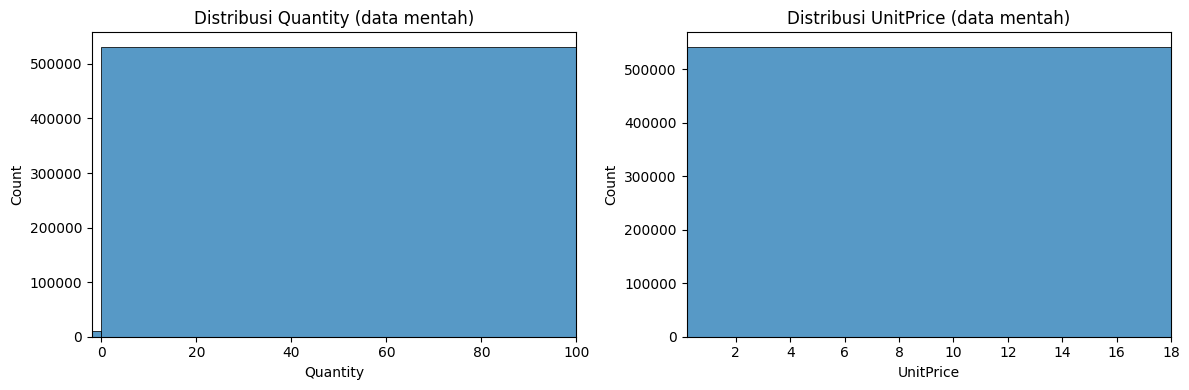

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Quantity"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("Distribusi Quantity (data mentah)")
axes[0].set_xlim(df["Quantity"].quantile(.01),
                 df["Quantity"].quantile(.99))

sns.histplot(df["UnitPrice"].dropna(), bins=50, ax=axes[1])
axes[1].set_title("Distribusi UnitPrice (data mentah)")
axes[1].set_xlim(df["UnitPrice"].quantile(.01),
                 df["UnitPrice"].quantile(.99))
plt.tight_layout()
plt.show()


## Laporan Kualitas Data (temuan, keputusan, dan risiko)


Berdasarkan hasil pemeriksaan dataset Online Retail, ditemukan beberapa permasalahan kualitas data yang perlu diperhatikan sebelum proses data preparation dan clustering dilakukan.

### 1. Missing Values

Ditemukan sebanyak 135.080 data kosong pada kolom CustomerID atau sekitar 24,93% dari keseluruhan data. Selain itu, terdapat 1.454 data kosong pada kolom Description atau sekitar 0,27%.

**Keputusan:** Transaksi tanpa CustomerID tidak digunakan dalam pembentukan profil RFM, tetapi tetap dipertahankan untuk EDA yang relevan. Sementara itu, Description kosong tidak langsung dihapus karena bukan fitur utama RFM.

**Risiko:** Penghapusan seluruh baris yang memiliki nilai kosong dapat menyebabkan transaksi yang sebenarnya valid ikut hilang.

### 2. Data Duplikat

Ditemukan sebanyak 5.268 baris duplikat dalam dataset.

**Keputusan:** Dilakukan pemeriksaan terhadap baris duplikat untuk memastikan bahwa data tersebut merupakan duplikasi identik sebelum memutuskan penghapusan.

**Risiko:** Penghapusan tanpa pemeriksaan dapat menyebabkan baris item transaksi yang sebenarnya valid ikut terhapus.

###  3. Quantity Tidak Valid

Ditemukan sebanyak 10.624 baris dengan Quantity kurang dari atau sama dengan nol. Nilai minimum Quantity adalah -80.995 dan nilai maksimumnya 80.995.

**Keputusan:** Nilai Quantity negatif diperiksa sebagai kemungkinan retur atau pembatalan. Untuk pembentukan baseline RFM, transaksi dengan Quantity tidak positif dipertimbangkan untuk dikeluarkan.

**Risiko:** Jika seluruh nilai negatif langsung dihapus, informasi mengenai retur dan pengaruhnya terhadap penjualan bersih tidak dapat dianalisis.

### 4. UnitPrice Tidak Valid

Ditemukan sebanyak 2.517 baris dengan UnitPrice kurang dari atau sama dengan nol. Nilai minimum UnitPrice adalah -11.062,06, sedangkan nilai maksimumnya 38.970.

**Keputusan:** Nilai nol dan negatif diperiksa lebih lanjut. Untuk baseline RFM, transaksi dengan UnitPrice tidak positif dipertimbangkan untuk dikeluarkan.

**Risiko:** Penghapusan tanpa pemeriksaan dapat menghilangkan transaksi khusus yang sebenarnya memiliki alasan pencatatan tertentu.

### 5. Invoice Pembatalan

Ditemukan sebanyak 9.288 baris dengan InvoiceNo yang diawali huruf C.

**Keputusan:** Invoice yang diawali huruf C diperlakukan sebagai indikasi pembatalan dan diperiksa sebelum digunakan dalam perhitungan RFM.

**Risiko:** Jika transaksi pembatalan dianggap sebagai penjualan biasa, perhitungan Frequency dan Monetary dapat menjadi tidak akurat.

### 6. Outlier dan Skewness

Berdasarkan statistik deskriptif, Quantity memiliki nilai maksimum 80.995 dan UnitPrice memiliki nilai maksimum 38.970. Nilai tersebut jauh lebih tinggi dibandingkan persentil 99% masing-masing fitur, yaitu 100 untuk Quantity dan 18 untuk UnitPrice.

Histogram menunjukkan bahwa sebagian besar data terkonsentrasi pada nilai yang relatif rendah, sehingga terdapat indikasi distribusi yang menceng ke kanan.

**Keputusan:** Nilai ekstrem tidak langsung dihapus. Penanganan akan dipertimbangkan berdasarkan konteks transaksi dan kebutuhan pemodelan. Transformasi log juga akan dipertimbangkan pada fitur Frequency dan Monetary.

**Risiko:** Jika seluruh nilai ekstrem dihapus, karakteristik pelanggan dengan transaksi bernilai besar dapat hilang. Sebaliknya, jika tidak ditangani, nilai ekstrem dapat memengaruhi proses clustering.

### 7. Kesimpulan Pemeriksaan Kualitas Data

Hasil pemeriksaan menunjukkan bahwa dataset Online Retail memiliki beberapa permasalahan kualitas data, meliputi missing values, duplikasi, transaksi pembatalan, nilai Quantity dan UnitPrice yang tidak valid, serta kemungkinan outlier dan skewness.

Oleh karena itu, diperlukan proses data cleaning dengan aturan yang jelas dan terdokumentasi. Setiap keputusan pembersihan harus mempertimbangkan karakteristik transaksi agar informasi yang masih valid tidak ikut hilang.

# **PRAKTIKUM 5 — EDA Transaksi dan Pola Bisnis**


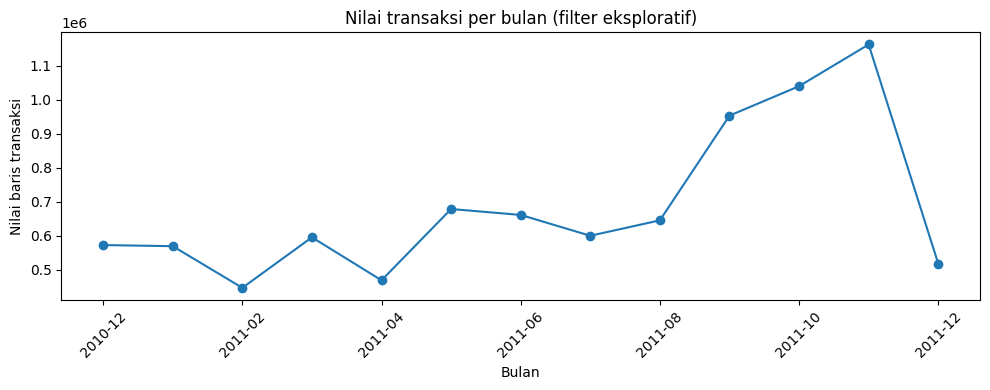

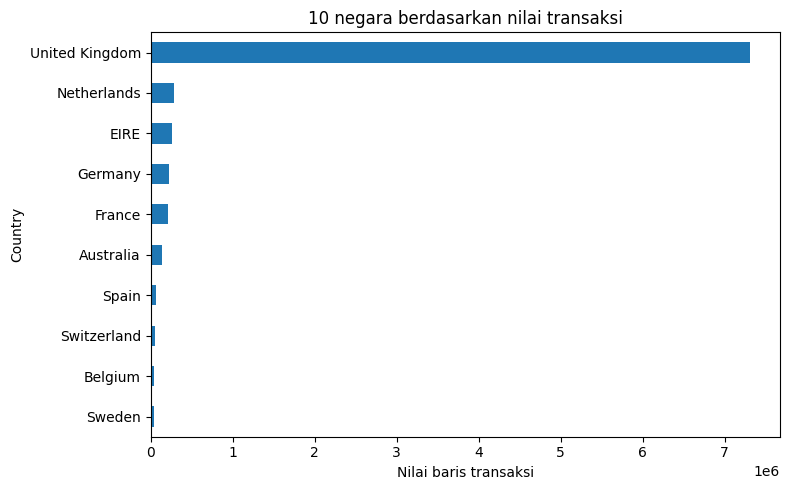

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54415
JUMBO BAG RED RETROSPOT,46181
WHITE HANGING HEART T-LIGHT HOLDER,36725
ASSORTED COLOUR BIRD ORNAMENT,35362
PACK OF 72 RETROSPOT CAKE CASES,33693
POPCORN HOLDER,30931
RABBIT NIGHT LIGHT,27202


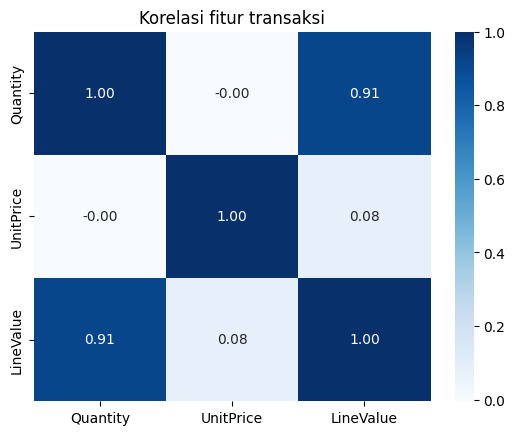

In [9]:
# Salinan untuk eksplorasi; belum menjadi data final clustering
eda = df.copy()
eda["LineValue"] = eda["Quantity"] * eda["UnitPrice"]
eda["Month"] = eda["InvoiceDate"].dt.to_period("M").astype(str)

# Tren nilai baris transaksi, gunakan data transaksi yang telah ditandai valid
valid_for_sales = eda[
    eda["CustomerID"].notna() &
    (eda["Quantity"] > 0) &
    (eda["UnitPrice"] > 0) &
    (~eda["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

monthly = valid_for_sales.groupby("Month")["LineValue"].sum()
monthly.plot(kind="line", marker="o", figsize=(10, 4))
plt.title("Nilai transaksi per bulan (filter eksploratif)")
plt.xlabel("Bulan"); plt.ylabel("Nilai baris transaksi")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Negara dengan nilai transaksi tertinggi
country_sales = (valid_for_sales.groupby("Country")["LineValue"]
                 .sum().sort_values(ascending=False).head(10))
country_sales.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("10 negara berdasarkan nilai transaksi")
plt.xlabel("Nilai baris transaksi"); plt.tight_layout(); plt.show()

# Produk dengan kuantitas tertinggi
product_qty = (valid_for_sales.groupby("Description")["Quantity"]
               .sum().sort_values(ascending=False).head(10))
display(product_qty)

# Korelasi antarfitur numerik pada baris transaksi
corr = valid_for_sales[["Quantity", "UnitPrice", "LineValue"]].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur transaksi"); plt.show()


## **Tugas**

1. Buat minimal empat grafik berbeda dan beri judul, label sumbu, serta satu paragraf interpretasi per grafik.


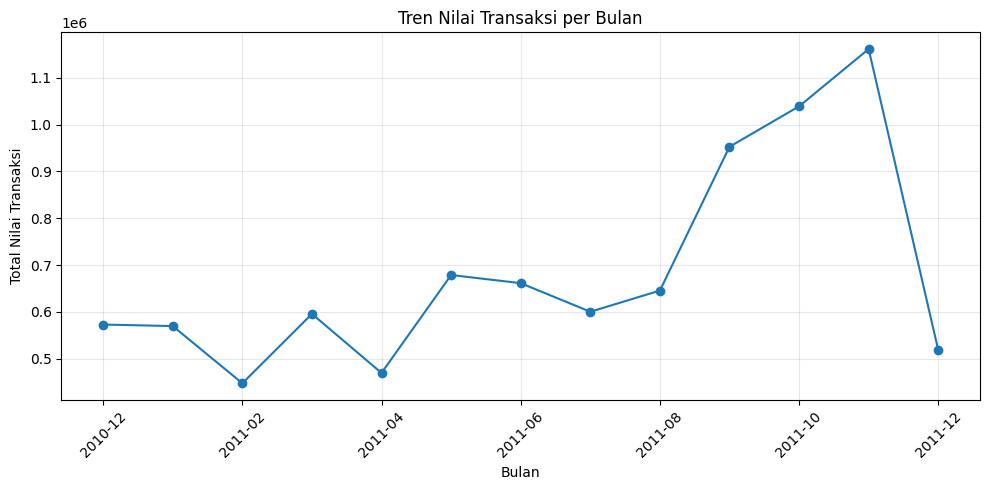

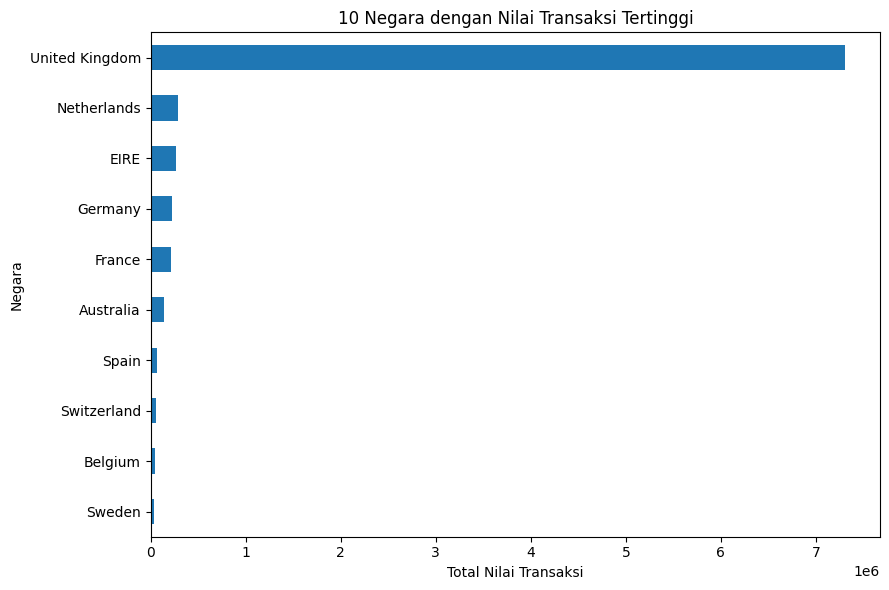

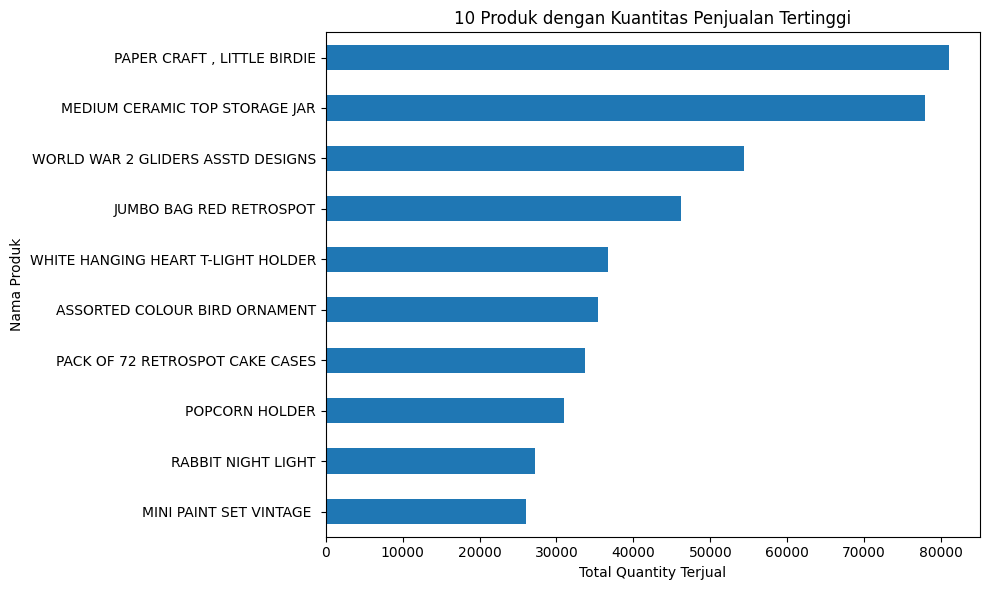

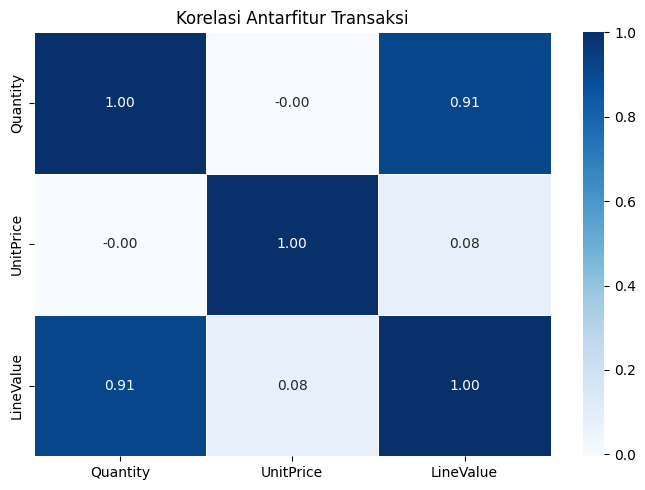

In [10]:


# Membuat 4 Grafik EDA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Salinan data untuk eksplorasi
eda = df.copy()

# Menghitung nilai transaksi per baris
eda["LineValue"] = eda["Quantity"] * eda["UnitPrice"]

# Membuat kolom bulan
eda["Month"] = eda["InvoiceDate"].dt.to_period("M").astype(str)

# Filter eksploratif untuk melihat penjualan
valid_for_sales = eda[
    eda["CustomerID"].notna() &
    (eda["Quantity"] > 0) &
    (eda["UnitPrice"] > 0) &
    (~eda["InvoiceNo"].astype(str).str.startswith("C"))
].copy()



# GRAFIK 1: TREN NILAI TRANSAKSI BULANAN


monthly = (
    valid_for_sales.groupby("Month")["LineValue"]
    .sum()
)

plt.figure(figsize=(10, 5))
monthly.plot(kind="line", marker="o")

plt.title("Tren Nilai Transaksi per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Total Nilai Transaksi")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# GRAFIK 2: 10 NEGARA DENGAN NILAI TRANSAKSI TERTINGGI


country_sales = (
    valid_for_sales.groupby("Country")["LineValue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(9, 6))
country_sales.sort_values().plot(kind="barh")

plt.title("10 Negara dengan Nilai Transaksi Tertinggi")
plt.xlabel("Total Nilai Transaksi")
plt.ylabel("Negara")
plt.tight_layout()
plt.show()



# GRAFIK 3: 10 PRODUK DENGAN KUANTITAS TERTINGGI


product_qty = (
    valid_for_sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
product_qty.sort_values().plot(kind="barh")

plt.title("10 Produk dengan Kuantitas Penjualan Tertinggi")
plt.xlabel("Total Quantity Terjual")
plt.ylabel("Nama Produk")
plt.tight_layout()
plt.show()



# GRAFIK 4: KORELASI FITUR TRANSAKSI


corr = valid_for_sales[
    ["Quantity", "UnitPrice", "LineValue"]
].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Korelasi Antarfitur Transaksi")
plt.tight_layout()
plt.show()


penjelasan 4 grafik  

## 1. Analisis Tren Nilai Transaksi Bulanan

Berdasarkan grafik tren nilai transaksi bulanan, terlihat bahwa nilai transaksi mengalami fluktuasi selama periode pengamatan. Peningkatan cukup signifikan mulai terlihat pada Agustus 2011 dan mencapai nilai tertinggi pada November 2011. Sementara itu, nilai transaksi pada Desember 2011 mengalami penurunan karena dataset hanya mencakup transaksi sampai tanggal 9 Desember 2011 sehingga belum mewakili satu bulan penuh.

## 2. Analisis Nilai Transaksi Berdasarkan Negara

Berdasarkan grafik 10 negara dengan nilai transaksi tertinggi, United Kingdom memiliki total nilai transaksi paling besar dibandingkan negara lainnya. Netherlands, EIRE, dan Germany berada pada posisi berikutnya dengan nilai transaksi yang lebih rendah. Hal ini menunjukkan bahwa aktivitas transaksi dalam dataset sangat didominasi oleh United Kingdom.

## 3. Analisis Produk dengan Kuantitas Penjualan Tertinggi

Berdasarkan grafik 10 produk dengan kuantitas penjualan tertinggi, PAPER CRAFT, LITTLE BIRDIE merupakan produk dengan jumlah penjualan tertinggi, yaitu 80.995 unit. Selanjutnya terdapat MEDIUM CERAMIC TOP STORAGE JAR sebanyak 77.916 unit dan WORLD WAR 2 GLIDERS ASSTD DESIGNS sebanyak 54.415 unit. Informasi ini dapat membantu perusahaan dalam mempertimbangkan pengelolaan persediaan produk.

## 4. Analisis Korelasi Antarfitur Transaksi

Berdasarkan heatmap korelasi, Quantity dan LineValue memiliki hubungan positif yang kuat dengan nilai korelasi sebesar 0,91. Sementara itu, hubungan UnitPrice dan LineValue sebesar 0,08, sedangkan hubungan Quantity dan UnitPrice mendekati nol. Hasil ini menunjukkan adanya hubungan yang berbeda antara jumlah barang, harga satuan, dan nilai transaksi. Namun, korelasi tidak membuktikan hubungan sebab-akibat.

2. Bandingkan distribusi Quantity dan UnitPrice dengan dan tanpa pembatasan kuantil untuk visualisasi.


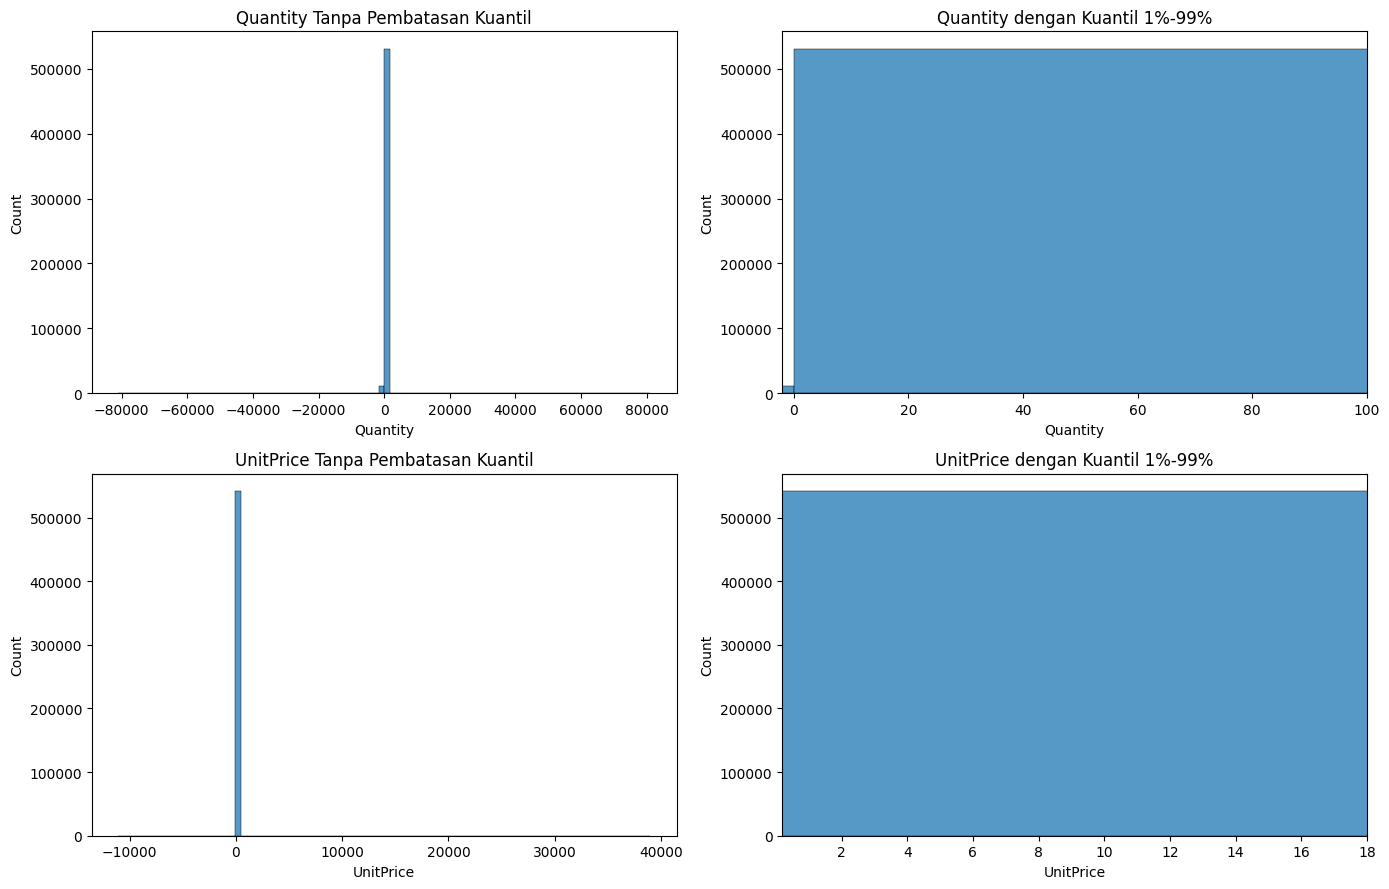

In [11]:

# PERBANDINGAN DISTRIBUSI DATA
# TANPA DAN DENGAN PEMBATASAN KUANTIL

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Quantity tanpa pembatasan
sns.histplot(df["Quantity"], bins=100, ax=axes[0, 0])
axes[0, 0].set_title("Quantity Tanpa Pembatasan Kuantil")
axes[0, 0].set_xlabel("Quantity")

# Quantity dengan pembatasan kuantil
sns.histplot(df["Quantity"], bins=100, ax=axes[0, 1])
axes[0, 1].set_xlim(
    df["Quantity"].quantile(0.01),
    df["Quantity"].quantile(0.99)
)
axes[0, 1].set_title("Quantity dengan Kuantil 1%-99%")
axes[0, 1].set_xlabel("Quantity")

# UnitPrice tanpa pembatasan
sns.histplot(df["UnitPrice"], bins=100, ax=axes[1, 0])
axes[1, 0].set_title("UnitPrice Tanpa Pembatasan Kuantil")
axes[1, 0].set_xlabel("UnitPrice")

# UnitPrice dengan pembatasan kuantil
sns.histplot(df["UnitPrice"], bins=100, ax=axes[1, 1])
axes[1, 1].set_xlim(
    df["UnitPrice"].quantile(0.01),
    df["UnitPrice"].quantile(0.99)
)
axes[1, 1].set_title("UnitPrice dengan Kuantil 1%-99%")
axes[1, 1].set_xlabel("UnitPrice")

plt.tight_layout()
plt.show()


Perbandingan distribusi Quantity dan UnitPrice menunjukkan bahwa pembatasan kuantil membantu memperjelas pola mayoritas data. Pada distribusi tanpa pembatasan, nilai ekstrem membuat sebagian besar data terlihat terkonsentrasi pada rentang yang sempit. Setelah tampilan dibatasi pada kuantil 1% hingga 99%, pola distribusi data utama menjadi lebih mudah diamati. Pembatasan tersebut hanya dilakukan untuk keperluan visualisasi dan tidak berarti nilai ekstrem langsung dihapus dari dataset.

3.Temukan dua pola yang mungkin penting bagi pengelola toko

- Pola 1 Peningkatan nilai transaksi menjelang akhir tahun

Nilai transaksi mengalami peningkatan cukup besar mulai Agustus 2011 dan mencapai puncaknya pada November 2011.

Implikasi bisnis: Pengelola toko dapat mengevaluasi kemungkinan peningkatan permintaan menjelang akhir tahun dan mempertimbangkan persediaan produk serta strategi promosi. Namun, penyebab kenaikan tersebut belum dapat dipastikan hanya dari grafik.

- Pola 2 Konsentrasi transaksi pada United Kingdom dan beberapa produk tertentu

United Kingdom mendominasi nilai transaksi berdasarkan negara. Selain itu, PAPER CRAFT, LITTLE BIRDIE dan MEDIUM CERAMIC TOP STORAGE JAR memiliki kuantitas penjualan tertinggi.

Implikasi bisnis: Pengelola toko dapat mempertimbangkan United Kingdom sebagai pasar utama dalam evaluasi penjualan dan memperhatikan ketersediaan stok produk dengan kuantitas tinggi.

4. Nyatakan apakah hasil EDA mengubah rencana awal fitur atau pembersihan data.


rencana awal tetap dipertahankan, tetapi ada beberapa hal yang perlu diperhatikan.

1. Fitur RFM tetap digunakan karena sudah sesuai dengan tujuan segmentasi pelanggan.
2. Transaksi tanpa CustomerID tetap dikeluarkan dari pembentukan RFM karena tidak dapat dihubungkan dengan pelanggan tertentu.
3. Invoice pembatalan serta Quantity dan UnitPrice yang tidak positif perlu ditangani secara eksplisit.
4. Nilai ekstrem tidak langsung dihapus karena bisa saja merupakan transaksi pembelian dalam jumlah besar yang valid.
5. Frequency dan Monetary nantinya dapat menggunakan transformasi log karena distribusinya berpotensi menceng ke kanan.

Jadi, hasil EDA tidak mengubah fitur utama, tetapi memperkuat alasan untuk melakukan pemeriksaan kualitas data dan transformasi sebelum clustering.

# **PRAKTIKUM 6 — Data Preparation: Pembersihan dan Nilai Transaksi**


In [12]:
# Salin data; pastikan tanggal sudah datetime
clean = df.copy()
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")
clean["CustomerID"] = clean["CustomerID"].astype("string").str.strip()

rows_before = len(clean)
duplicate_count = clean.duplicated().sum()
clean = clean.drop_duplicates()

# Baris yang dapat dipakai untuk profil pelanggan
clean = clean[clean["CustomerID"].notna()].copy()
clean = clean[clean["InvoiceDate"].notna()].copy()

# Baseline: transaksi pembelian positif, bukan invoice pembatalan
is_cancellation = clean["InvoiceNo"].astype(str).str.startswith("C")
clean = clean[~is_cancellation]
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]

clean["LineValue"] = clean["Quantity"] * clean["UnitPrice"]

print("Baris awal:", rows_before)
print("Duplikat identik terdeteksi:", duplicate_count)
print("Baris setelah baseline cleaning:", len(clean))
print("Pelanggan tersedia:", clean["CustomerID"].nunique())
display(clean.head())


Baris awal: 541909
Duplikat identik terdeteksi: 5268
Baris setelah baseline cleaning: 392692
Pelanggan tersedia: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## pemeriksaan setelah cleaning

In [13]:
assert clean["CustomerID"].notna().all()
assert clean["InvoiceDate"].notna().all()
assert (clean["Quantity"] > 0).all()
assert (clean["UnitPrice"] > 0).all()
assert (clean["LineValue"] > 0).all()

print(clean[["Quantity", "UnitPrice", "LineValue"]].describe())


            Quantity      UnitPrice      LineValue
count  392692.000000  392692.000000  392692.000000
mean       13.119702       3.125914      22.631500
std       180.492832      22.241836     311.099224
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.950000
50%         6.000000       1.950000      12.450000
75%        12.000000       3.750000      19.800000
max     80995.000000    8142.750000  168469.600000


## Tugas


1. Bandingkan jumlah baris dan jumlah pelanggan sebelum serta sesudah cleaning.

Berdasarkan proses data cleaning, jumlah data awal sebanyak 541.909 baris dengan 8 kolom dan 4.372 pelanggan unik. Setelah dilakukan proses pembersihan, jumlah data menjadi 392.692 baris dengan 9 kolom dan 4.338 pelanggan unik.

Dengan demikian, terdapat pengurangan sebanyak 149.217 baris dan 34 pelanggan unik yang tidak lagi muncul dalam data bersih. Jumlah kolom bertambah menjadi 9 karena terdapat penambahan fitur LineValue yang dihitung dari perkalian Quantity dan UnitPrice.

2. Buat tabel log pembersihan: aturan, jumlah baris terdampak, alasan, risiko.

In [14]:

# LOG DATA CLEANING - PRAKTIKUM 6

log = []

# Salinan data mentah
log_clean = df.copy()

log_clean["InvoiceDate"] = pd.to_datetime(
    log_clean["InvoiceDate"], errors="coerce"
)
log_clean["CustomerID"] = (
    log_clean["CustomerID"].astype("string").str.strip()
)

# Fungsi untuk mencatat jumlah baris terdampak
def catat_log(aturan, jumlah, alasan, risiko):
    log.append({
        "Aturan": aturan,
        "Jumlah baris terdampak": jumlah,
        "Alasan": alasan,
        "Risiko jika salah": risiko
    })


# Jumlah baris awal
baris_awal = len(log_clean)

# 1. Menghapus duplikasi identik
jumlah_duplikat = log_clean.duplicated().sum()
log_clean = log_clean.drop_duplicates()

catat_log(
    "Menghapus duplikasi identik",
    jumlah_duplikat,
    "Menghindari pencatatan transaksi yang sama lebih dari satu kali.",
    "Jika baris sebenarnya merupakan item transaksi yang sah, data valid dapat hilang."
)


# 2. Mengeluarkan CustomerID kosong
jumlah_customer_kosong = log_clean["CustomerID"].isna().sum()
log_clean = log_clean[log_clean["CustomerID"].notna()].copy()

catat_log(
    "Mengeluarkan CustomerID kosong",
    jumlah_customer_kosong,
    "Data tanpa identitas pelanggan tidak dapat digunakan untuk membentuk profil RFM.",
    "Informasi transaksi tanpa identitas pelanggan tidak dapat digunakan dalam segmentasi."
)


# 3. Mengeluarkan InvoiceDate kosong/tidak valid
jumlah_tanggal_kosong = log_clean["InvoiceDate"].isna().sum()
log_clean = log_clean[log_clean["InvoiceDate"].notna()].copy()

catat_log(
    "Mengeluarkan InvoiceDate kosong/tidak valid",
    jumlah_tanggal_kosong,
    "Tanggal diperlukan untuk menghitung Recency dan menganalisis waktu transaksi.",
    "Transaksi valid dapat hilang jika format tanggal sebenarnya masih dapat diperbaiki."
)


# 4. Mengeluarkan invoice pembatalan
is_cancellation = (
    log_clean["InvoiceNo"].astype(str).str.startswith("C")
)
jumlah_pembatalan = is_cancellation.sum()
log_clean = log_clean[~is_cancellation].copy()

catat_log(
    "Mengeluarkan invoice diawali C",
    jumlah_pembatalan,
    "Invoice yang diawali C diperlakukan sebagai indikasi pembatalan.",
    "Jika penanda C tidak selalu berarti pembatalan, transaksi valid dapat ikut dikeluarkan."
)


# 5. Mengeluarkan Quantity <= 0
jumlah_quantity = (log_clean["Quantity"] <= 0).sum()
log_clean = log_clean[log_clean["Quantity"] > 0].copy()

catat_log(
    "Mengeluarkan Quantity <= 0",
    jumlah_quantity,
    "Baseline analisis hanya menggunakan transaksi dengan jumlah barang positif.",
    "Informasi retur atau pencatatan khusus dapat hilang."
)


# 6. Mengeluarkan UnitPrice <= 0
jumlah_unitprice = (log_clean["UnitPrice"] <= 0).sum()
log_clean = log_clean[log_clean["UnitPrice"] > 0].copy()

catat_log(
    "Mengeluarkan UnitPrice <= 0",
    jumlah_unitprice,
    "Baseline analisis hanya menggunakan transaksi dengan harga positif.",
    "Transaksi khusus dengan harga nol atau negatif dapat ikut dikeluarkan."
)


# Membuat LineValue
log_clean["LineValue"] = (
    log_clean["Quantity"] * log_clean["UnitPrice"]
)

# Menampilkan tabel log
log_df = pd.DataFrame(log)

display(log_df)

print("Jumlah baris awal:", baris_awal)
print("Jumlah baris akhir:", len(log_clean))
print("Jumlah baris yang dikeluarkan:", baris_awal - len(log_clean))
print("Jumlah pelanggan akhir:", log_clean["CustomerID"].nunique())

# Memastikan hasil sama dengan cleaning utama
print("Sama dengan clean utama:", len(log_clean) == len(clean))


,Aturan,Jumlah baris terdampak,Alasan,Risiko jika salah
0,Menghapus duplikasi identik,5268,Menghindari pencatatan transaksi yang sama leb...,Jika baris sebenarnya merupakan item transaksi...
1,Mengeluarkan CustomerID kosong,135037,Data tanpa identitas pelanggan tidak dapat dig...,Informasi transaksi tanpa identitas pelanggan ...
2,Mengeluarkan InvoiceDate kosong/tidak valid,0,Tanggal diperlukan untuk menghitung Recency da...,Transaksi valid dapat hilang jika format tangg...
3,Mengeluarkan invoice diawali C,8872,Invoice yang diawali C diperlakukan sebagai in...,Jika penanda C tidak selalu berarti pembatalan...
4,Mengeluarkan Quantity <= 0,0,Baseline analisis hanya menggunakan transaksi ...,Informasi retur atau pencatatan khusus dapat h...
5,Mengeluarkan UnitPrice <= 0,40,Baseline analisis hanya menggunakan transaksi ...,Transaksi khusus dengan harga nol atau negatif...


Jumlah baris awal: 541909
Jumlah baris akhir: 392692
Jumlah baris yang dikeluarkan: 149217
Jumlah pelanggan akhir: 4338
Sama dengan clean utama: True


Penjelasan log pembersihan data

Proses pembersihan dilakukan secara bertahap dengan menerapkan beberapa aturan, yaitu:

1. Menghapus baris duplikat identik untuk menghindari pencatatan transaksi yang sama lebih dari satu kali.

2. Mengeluarkan data yang tidak memiliki CustomerID karena tidak dapat digunakan untuk membentuk profil pelanggan.

3. Mengeluarkan data dengan InvoiceDate kosong atau tidak valid karena tanggal diperlukan dalam perhitungan Recency.

4. Mengeluarkan invoice yang diawali huruf C karena diperlakukan sebagai indikasi pembatalan.

5. Mengeluarkan transaksi dengan Quantity kurang dari atau sama dengan nol.

6. Mengeluarkan transaksi dengan UnitPrice kurang dari atau sama dengan nol.

Jumlah baris yang terdampak pada setiap aturan dicatat dalam tabel log pembersihan berdasarkan urutan proses cleaning.

3. Jelaskan mengapa data bersih harus tetap disimpan terpisah dari data mentah.

Data mentah (df) dan data bersih (clean) sebaiknya tidak digabung atau saling menimpa karena memiliki fungsi yang berbeda.

1. Menjaga data asli Data mentah tetap tersedia sebagai sumber awal sebelum dilakukan perubahan.
2. Memudahkan pemeriksaan Jika terdapat kesalahan dalam aturan cleaning, kita bisa membandingkan hasilnya dengan data asli.
3. Mendukung eksperimen Kita dapat mencoba aturan cleaning yang berbeda tanpa harus mengunduh ulang dataset.
4. Menjaga  keterlacakan
Setiap perubahan dapat dicatat sehingga proses analisis lebih transparan dan dapat diulang.

Contohnya, jika nanti kita ingin membandingkan hasil segmentasi dengan dan tanpa penanganan outlier, data mentah masih tersedia sebagai pembanding.

# **PRAKTIKUM 7 — Membentuk Fitur Pelanggan RFM**

In [15]:
# Tanggal acuan dibuat satu hari setelah tanggal transaksi terakhir
reference_date = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineValue", "sum")
)
rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()

print("Ukuran tabel RFM:", rfm.shape)
display(rfm.head())
display(rfm.describe().T)
print("CustomerID unik:", rfm.index.nunique())


Ukuran tabel RFM: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,3,7,4310.00
12348.0,76,4,1797.24
12349.0,19,1,1757.55
12350.0,311,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.00,18.0000,51.00,142.7500,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


CustomerID unik: 4338


## EDA khusus RFM

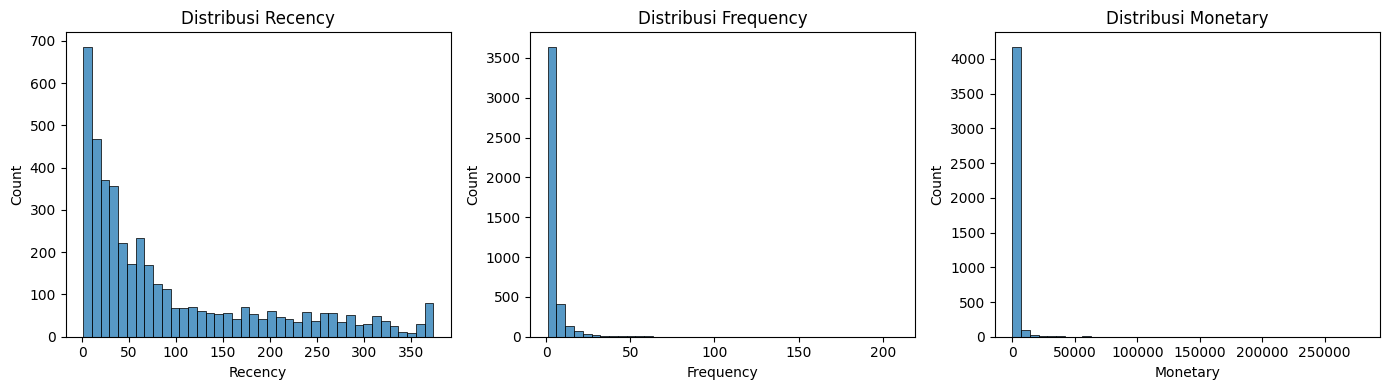

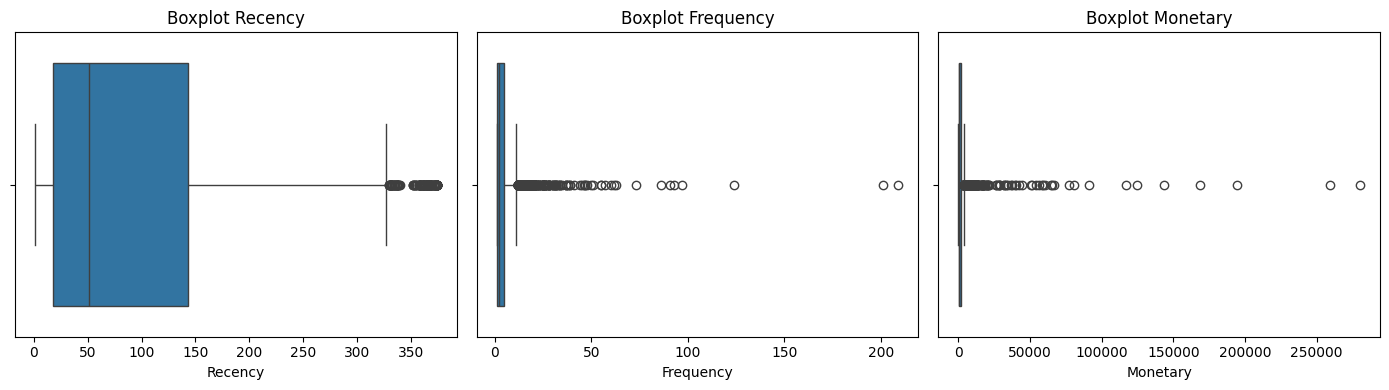

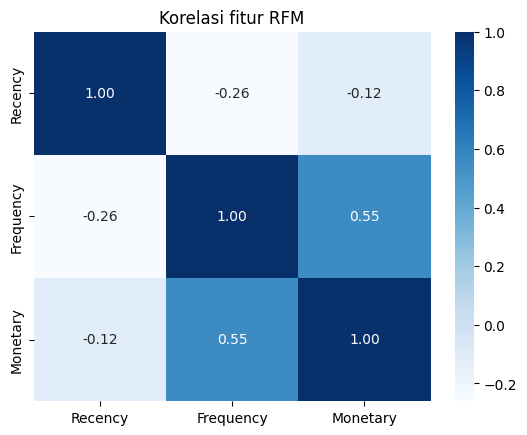

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"Boxplot {col}")
plt.tight_layout(); plt.show()

sns.heatmap(rfm.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur RFM"); plt.show()


## Menangani skewness

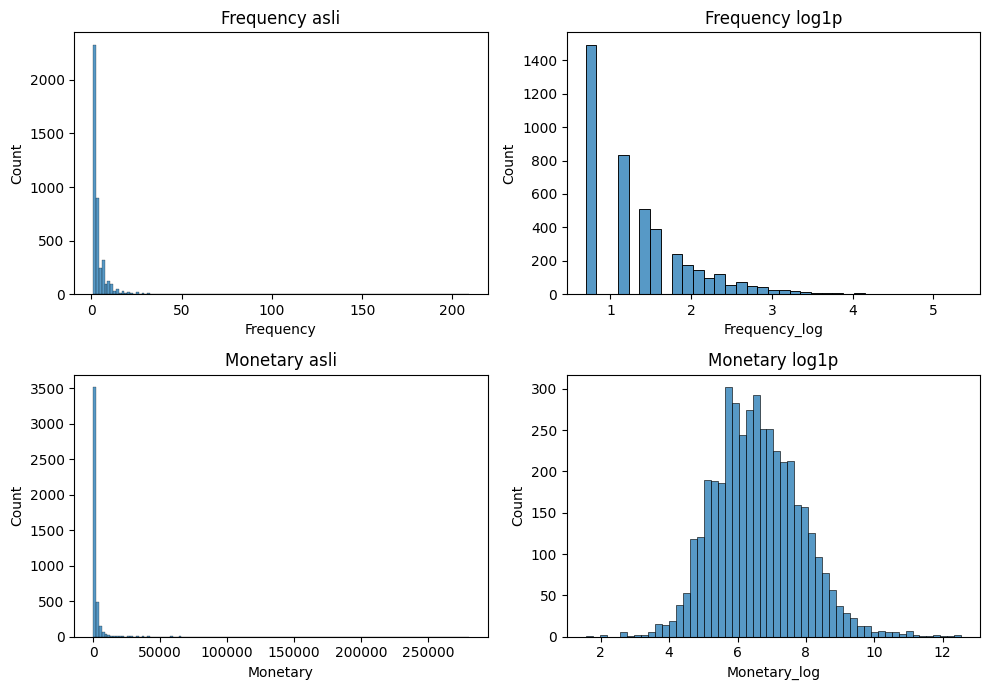

In [17]:
rfm_model = rfm.copy()
rfm_model["Frequency_log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_log"] = np.log1p(rfm_model["Monetary"])

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(rfm_model["Frequency"], ax=axes[0,0])
axes[0,0].set_title("Frequency asli")
sns.histplot(rfm_model["Frequency_log"], ax=axes[0,1])
axes[0,1].set_title("Frequency log1p")
sns.histplot(rfm_model["Monetary"], ax=axes[1,0])
axes[1,0].set_title("Monetary asli")
sns.histplot(rfm_model["Monetary_log"], ax=axes[1,1])
axes[1,1].set_title("Monetary log1p")
plt.tight_layout(); plt.show()


## Menentukan fitur final

In [18]:
features = rfm_model[["Recency", "Frequency_log", "Monetary_log"]].copy()
print(features.isna().sum())
display(features.head())


Recency          0
Frequency_log    0
Monetary_log     0
dtype: int64


,Recency,Frequency_log,Monetary_log
CustomerID,,,
12346.0,326,0.693147,11.253955
12347.0,3,2.079442,8.368925
12348.0,76,1.609438,7.494564
12349.0,19,0.693147,7.472245
12350.0,311,0.693147,5.815324


## Tugas

1. Jelaskan perbedaan unit analisis pada dataset transaksi dan tabel RFM.

Dataset transaksi:

Satu baris mewakili satu item produk dalam suatu transaksi. Artinya, satu invoice dapat memiliki beberapa baris karena pelanggan bisa membeli beberapa jenis produk dalam satu transaksi.

Tabel RFM:

Satu baris mewakili satu pelanggan. Seluruh transaksi milik pelanggan yang sama digabungkan untuk menghasilkan nilai Recency, Frequency, dan Monetary.

Kesimpulan: Dataset transaksi berfokus pada aktivitas pembelian per item, sedangkan tabel RFM berfokus pada perilaku pembelian setiap pelanggan.

2. Interpretasikan pelanggan dengan Recency kecil tetapi Frequency dan Monetary rendah.

Pelanggan dengan Recency kecil berarti baru saja melakukan transaksi. Namun, Frequency dan Monetary yang rendah menunjukkan bahwa pelanggan tersebut belum sering bertransaksi dan total nilai pembeliannya masih relatif kecil.

Pelanggan seperti ini dapat diinterpretasikan sebagai pelanggan baru atau pelanggan yang melakukan pembelian sesekali dengan nilai transaksi rendah.

Dari sisi bisnis, pengelola toko dapat mempertimbangkan strategi pemasaran seperti rekomendasi produk, promosi pembelian berikutnya, atau program pengenalan produk untuk mendorong pelanggan melakukan transaksi kembali.

3. Bandingkan histogram Frequency dan Monetary sebelum dan sesudah log1p.

Frequency sebelum log1p:
- Sebagian besar pelanggan memiliki jumlah transaksi yang relatif sedikit.
- Hanya sebagian kecil pelanggan yang melakukan transaksi dalam jumlah sangat banyak.
- Distribusi menceng ke kanan dan memiliki nilai ekstrem hingga 209 transaksi.

Frequency sesudah log1p:
- Rentang nilai menjadi lebih terkompresi.
- Perbedaan antara pelanggan dengan transaksi sedikit dan sangat banyak menjadi tidak terlalu ekstrem.
- Distribusi masih menunjukkan kemencengan ke kanan, tetapi pola data lebih mudah diamati.

Monetary sebelum log1p:
- Sebagian besar pelanggan memiliki total pembelian relatif rendah.
- Terdapat beberapa pelanggan dengan total pembelian sangat tinggi.
- Nilai maksimum mencapai 280.206,02 sehingga distribusi sangat menceng ke kanan.

Monetary sesudah log1p:
- Rentang nilai menjadi lebih terkompresi.
- Distribusi terlihat jauh lebih mendekati bentuk lonceng dibandingkan Monetary asli.
- Pengaruh perbedaan nilai yang sangat besar menjadi lebih terkendali.

Kesimpulan: Transformasi log1p membantu mengurangi kemencengan distribusi Frequency dan Monetary sehingga kedua fitur lebih siap digunakan dalam proses clustering.




4. Jelaskan mengapa CustomerID tidak dimasukkan ke features.


CustomerID merupakan kode pengenal pelanggan, bukan ukuran perilaku transaksi pelanggan.

Jika CustomerID dimasukkan sebagai fitur clustering, algoritma dapat memperlakukan perbedaan nomor identitas sebagai perbedaan karakteristik pelanggan. Padahal, nomor CustomerID tidak menunjukkan seberapa sering pelanggan bertransaksi, kapan terakhir bertransaksi, atau berapa nilai pembeliannya.

Oleh karena itu, CustomerID hanya digunakan sebagai identitas atau indeks untuk menghubungkan hasil cluster dengan pelanggan yang bersangkutan. Fitur clustering tetap menggunakan Recency, Frequency_log, dan Monetary_log.

# **PRAKTIKUM 8 — Modeling: K-Means**

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

results_kmeans = []
models_kmeans = {}
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)
    results_kmeans.append({
        "k": k, "inertia": model.inertia_,
        "silhouette": sil, "davies_bouldin": dbi
    })
    models_kmeans[k] = model

metrics_kmeans = pd.DataFrame(results_kmeans)
display(metrics_kmeans)


,k,inertia,silhouette,davies_bouldin
0,2,6874.047281,0.406287,0.915325
1,3,4299.200976,0.415654,0.824915
2,4,3242.934841,0.379421,0.859949
3,5,2760.683135,0.343462,0.940980
4,6,2396.802728,0.331644,0.969220
5,7,2167.087137,0.300838,1.018503


## Elbow dan Silhouette

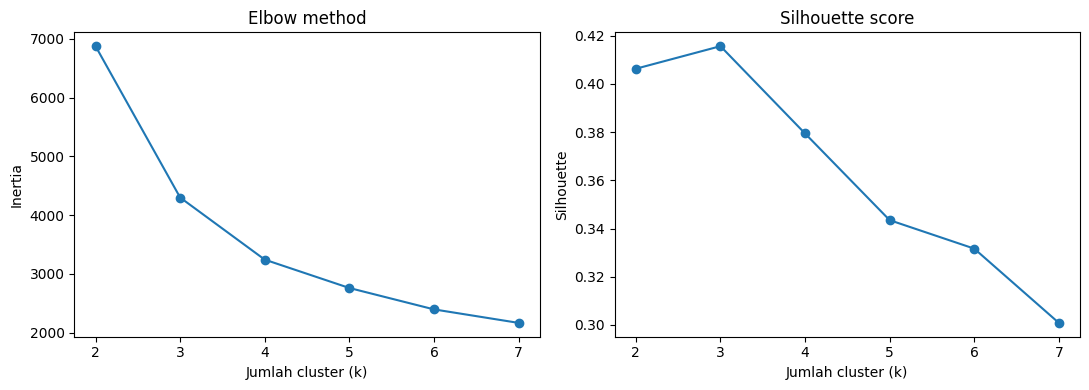

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(metrics_kmeans["k"], metrics_kmeans["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(metrics_kmeans["k"], metrics_kmeans["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()


## Memilih model sementara

In [21]:
# Pilih k berdasarkan kombinasi metrik dan interpretasi.
# Contoh otomatis di bawah memilih silhouette tertinggi; keputusan final tetap harus ditinjau.
best_k = int(metrics_kmeans.loc[metrics_kmeans["silhouette"].idxmax(), "k"])
kmeans_model = models_kmeans[best_k]
rfm["KMeans_Cluster"] = kmeans_model.labels_
print("k terpilih sementara:", best_k)
display(rfm.groupby("KMeans_Cluster")[["Recency","Frequency","Monetary"]]
        .median().round(2))


k terpilih sementara: 3


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,46.0,2.0,508.80
1,253.0,1.0,290.46
2,18.0,7.0,2570.50


## Visualisasi dua fitur

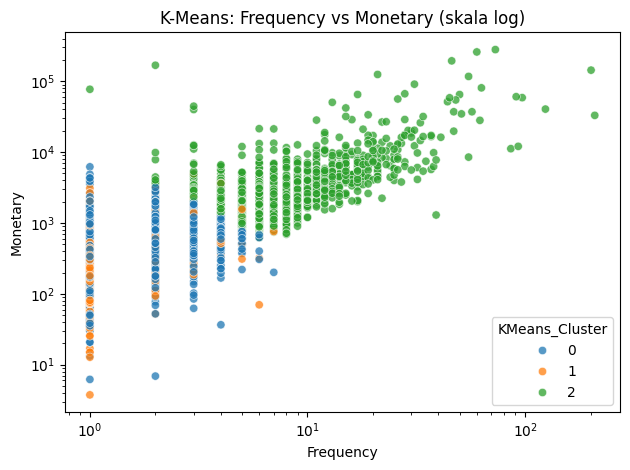

In [22]:
sns.scatterplot(
    data=rfm, x="Frequency", y="Monetary",
    hue="KMeans_Cluster", palette="tab10", alpha=.75
)
plt.xscale("log")
plt.yscale("log")
plt.title("K-Means: Frequency vs Monetary (skala log)")
plt.tight_layout(); plt.show()


## Pertanyaan


1. Apa makna inertia dan mengapa nilainya cenderung turun saat k bertambah?

Inertia merupakan ukuran jumlah kuadrat jarak antara setiap data pelanggan dengan pusat cluster (centroid) tempat pelanggan tersebut dikelompokkan.

Semakin kecil nilai inertia, semakin dekat data pelanggan dengan centroid cluster masing-masing. Nilai inertia cenderung turun ketika jumlah cluster bertambah karena data dibagi menjadi kelompok yang lebih banyak sehingga jarak setiap data terhadap centroid dapat menjadi lebih kecil.

Namun, inertia yang semakin kecil tidak selalu berarti model semakin baik. Oleh karena itu, diperlukan metrik evaluasi lain seperti Silhouette Score dan Davies–Bouldin Index.

2. Apa kelebihan dan keterbatasan Elbow Method?

Kelebihan:
- Mudah digunakan untuk menentukan perkiraan jumlah cluster.
- Membantu melihat hubungan antara jumlah cluster dan nilai inertia.
- Dapat memberikan gambaran kapan penambahan cluster mulai memberikan manfaat yang semakin kecil.


Keterbatasan:
- Titik siku pada grafik terkadang tidak terlihat dengan jelas.
- Penentuan titik siku dapat bersifat subjektif.
- Tidak secara langsung mengukur kualitas pemisahan antarcluster.
- Hasilnya perlu dibandingkan dengan metrik evaluasi dan interpretasi bisnis.

3. Mengapa hasil cluster perlu ditafsirkan menggunakan RFM asli?

Hasil clustering perlu ditafsirkan menggunakan RFM asli karena fitur yang digunakan dalam proses pemodelan telah melalui transformasi log1p dan standardisasi.

Nilai hasil transformasi tidak selalu mudah dipahami dalam konteks bisnis. Dengan menggunakan RFM asli, kita dapat mengetahui jumlah hari sejak transaksi terakhir, jumlah transaksi pelanggan, serta total nilai pembeliannya.

Hal ini membuat hasil segmentasi lebih mudah dipahami dan dapat digunakan untuk menyusun strategi pemasaran yang sesuai dengan karakteristik setiap kelompok pelanggan.

4. Apakah k dengan Silhouette tertinggi otomatis menjadi pilihan terbaik? Jelaskan.


Tidak. Nilai Silhouette tertinggi tidak otomatis menjadikan suatu jumlah cluster sebagai pilihan terbaik.

Pemilihan jumlah cluster perlu mempertimbangkan beberapa aspek, seperti nilai Inertia, Silhouette Score, Davies–Bouldin Index, ukuran setiap cluster, serta kemudahan interpretasi hasil segmentasi dari sisi bisnis.

Dalam percobaan ini, k = 3 menjadi kandidat terbaik karena memiliki Silhouette Score tertinggi sebesar 0,415654 dan Davies–Bouldin Index terendah sebesar 0,824915. Selain itu, ketiga cluster menghasilkan profil pelanggan yang cukup mudah dibedakan berdasarkan nilai RFM.

# **PRAKTIKUM 9 — Modeling: K-Medoid**s

In [23]:
# Pilihan A — coba instalasi paket
%pip -q install scikit-learn-extra

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Jalankan jika paket berhasil diinstal
kmedoids_results = []
kmedoids_models = {}
for k in range(2, 8):
    model = KMedoids(n_clusters=k, random_state=42,
                     metric="euclidean", method="alternate",
                     init="k-medoids++")
    labels = model.fit_predict(X_scaled)
    kmedoids_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    kmedoids_models[k] = model

metrics_kmedoids = pd.DataFrame(kmedoids_results)
display(metrics_kmedoids)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


,k,silhouette,davies_bouldin
0,2,0.395125,0.915266
1,3,0.413914,0.825647
2,4,0.372484,0.868534
3,5,0.354828,0.964474
4,6,0.291199,1.109641
5,7,0.319186,1.014629


## Tugas

1. Bandingkan prinsip centroid K-Means dengan medoid K-Medoids.

K-Means merupakan algoritma clustering yang menggunakan centroid sebagai pusat cluster. Centroid diperoleh dari rata-rata posisi seluruh data yang termasuk dalam cluster tersebut sehingga pusat cluster tidak harus merupakan data aktual.

Sementara itu, K-Medoids menggunakan medoid sebagai pusat cluster, yaitu salah satu objek aktual yang dipilih untuk mewakili kelompoknya.

K-Medoids cenderung lebih tahan terhadap pengaruh outlier tertentu karena pusat clusternya berasal dari objek aktual, sedangkan K-Means dapat lebih terpengaruh oleh nilai ekstrem. Namun, K-Medoids umumnya membutuhkan waktu komputasi lebih besar.

2. Perbandingan Jumlah Cluster yang Sama

Perbandingan awal dilakukan menggunakan jumlah cluster yang sama, yaitu k = 3. Pemilihan ini didasarkan pada hasil Praktikum 8, ketika K-Means memperoleh nilai evaluasi terbaik pada tiga cluster.

Dengan menggunakan jumlah cluster yang sama, hasil kedua algoritma dapat dibandingkan secara lebih adil berdasarkan metrik evaluasi dan karakteristik pelanggan.

3. Membandingkan waktu komputasi dan kualitas model


In [24]:

import time
import pandas as pd

from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Jumlah cluster yang sama
k = 3

# 1. K-MEANS

start_kmeans = time.perf_counter()

model_kmeans_3 = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

labels_kmeans = model_kmeans_3.fit_predict(X_scaled)

time_kmeans = time.perf_counter() - start_kmeans

sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
dbi_kmeans = davies_bouldin_score(X_scaled, labels_kmeans)

# 2. K-MEDOIDS
start_kmedoids = time.perf_counter()

model_kmedoids_3 = KMedoids(
    n_clusters=k,
    random_state=42,
    metric="euclidean",
    method="alternate",
    init="k-medoids++"
)

labels_kmedoids = model_kmedoids_3.fit_predict(X_scaled)

time_kmedoids = time.perf_counter() - start_kmedoids

sil_kmedoids = silhouette_score(X_scaled, labels_kmedoids)
dbi_kmedoids = davies_bouldin_score(X_scaled, labels_kmedoids)


# 3. TABEL PERBANDINGAN

comparison = pd.DataFrame({
    "Algoritma": ["K-Means", "K-Medoids"],
    "Jumlah Cluster": [k, k],
    "Waktu Komputasi (detik)": [
        time_kmeans,
        time_kmedoids
    ],
    "Silhouette Score": [
        sil_kmeans,
        sil_kmedoids
    ],
    "Davies-Bouldin Index": [
        dbi_kmeans,
        dbi_kmedoids
    ]
})

display(comparison.round(6))


,Algoritma,Jumlah Cluster,Waktu Komputasi (detik),Silhouette Score,Davies-Bouldin Index
0,K-Means,3,0.054070,0.415654,0.824915
1,K-Medoids,3,4.533408,0.413914,0.825647


Berdasarkan hasil pengujian sebelumnya, diperoleh:

K-Means memiliki Silhouette Score sebesar 0,415654 dan Davies–Bouldin Index sebesar 0,824915.

K-Medoids memiliki Silhouette Score sebesar 0,413914 dan Davies–Bouldin Index sebesar 0,825647.

K-Means memperoleh Silhouette Score sedikit lebih tinggi dan Davies–Bouldin Index sedikit lebih rendah dibandingkan K-Medoids. Hal ini menunjukkan bahwa K-Means sedikit lebih baik berdasarkan kedua metrik pada percobaan ini.

Waktu komputasi masing-masing algoritma dicatat berdasarkan hasil pengukuran pada Google Colab.

# Membuat profil cluster K-Medoids

In [25]:

# PROFIL CLUSTER K-MEDOIDS

rfm["KMedoids_Cluster"] = labels_kmedoids

print("Profil Cluster K-Medoids:")

profile_kmedoids = (
    rfm.groupby("KMedoids_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ]
    .median()
    .round(2)
)

display(profile_kmedoids)

# Jumlah pelanggan setiap cluster
print("Jumlah pelanggan per cluster:")

display(
    rfm["KMedoids_Cluster"]
    .value_counts()
    .sort_index()
)


Profil Cluster K-Medoids:


,Recency,Frequency,Monetary
KMedoids_Cluster,,,
0,47.0,2.0,500.42
1,254.0,1.0,283.71
2,18.0,7.0,2479.05


Jumlah pelanggan per cluster:


,count
KMedoids_Cluster,
0,1989
1,969
2,1380


In [26]:

# PERBANDINGAN PROFIL K-MEANS DAN K-MEDOIDS

profile_kmeans = (
    rfm.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ]
    .median()
    .round(2)
)

print("Profil K-Means:")
display(profile_kmeans)

print("Profil K-Medoids:")
display(profile_kmedoids)


Profil K-Means:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,46.0,2.0,508.80
1,253.0,1.0,290.46
2,18.0,7.0,2570.50


Profil K-Medoids:


,Recency,Frequency,Monetary
KMedoids_Cluster,,,
0,47.0,2.0,500.42
1,254.0,1.0,283.71
2,18.0,7.0,2479.05


Hasil clustering perlu dianalisis menggunakan median Recency, Frequency, dan Monetary asli. Hal ini bertujuan agar karakteristik setiap kelompok pelanggan dapat dipahami berdasarkan perilaku transaksi sebenarnya.

Perbandingan interpretasi dilakukan dengan memperhatikan pelanggan yang baru bertransaksi, frekuensi pembelian, serta total nilai pembelian pada masing-masing cluster.

4. Jelaskan mengapa perbandingan pada sampel harus disebutkan sebagai keterbatasan.

Apabila pemodelan K-Medoids dilakukan menggunakan sampel data, hasilnya memiliki keterbatasan karena tidak seluruh pelanggan dilibatkan dalam proses pembentukan cluster.

Hasil pada sampel belum tentu sepenuhnya mewakili karakteristik seluruh pelanggan. Pemilihan sampel juga dapat memengaruhi pusat cluster, nilai evaluasi, dan interpretasi segmentasi.

Oleh karena itu, penggunaan sampel harus dicatat secara jelas, termasuk jumlah data yang digunakan dan metode pengambilan sampelnya.

# **PRAKTIKUM 10 — Modeling: Hierarchical Clustering**

In [27]:
from sklearn.cluster import AgglomerativeClustering

hier_results = []
hier_models = {}
for k in range(2, 8):
    model = AgglomerativeClustering(
        n_clusters=k, linkage="ward"
    )
    labels = model.fit_predict(X_scaled)
    hier_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    hier_models[k] = model

metrics_hier = pd.DataFrame(hier_results)
display(metrics_hier)


,k,silhouette,davies_bouldin
0,2,0.382603,0.956354
1,3,0.364925,0.855645
2,4,0.336078,0.921027
3,5,0.290059,1.022131
4,6,0.275625,0.998258
5,7,0.223598,1.084314


## Visuallisasi

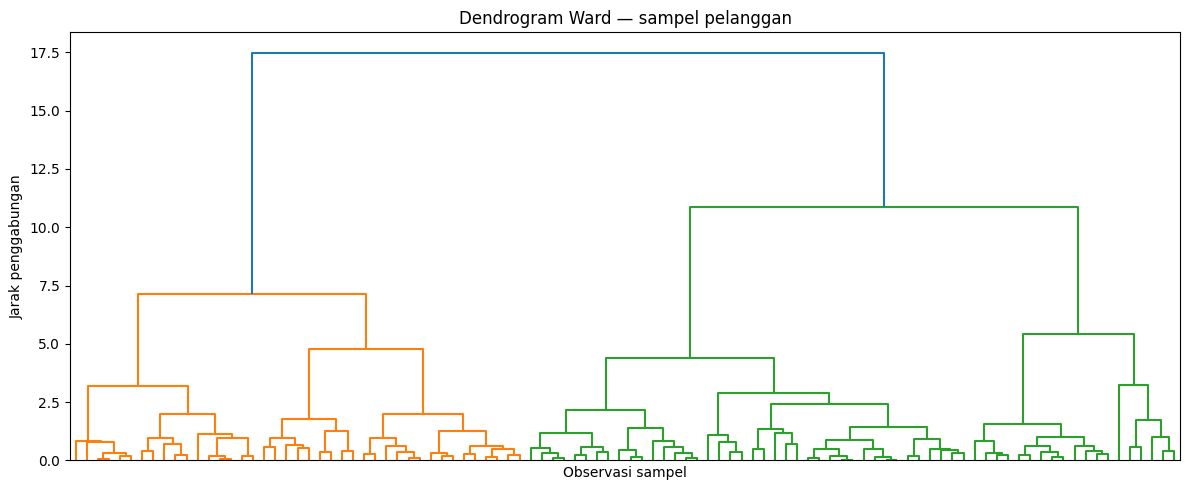

In [28]:
# Visualisasi pada sampel kecil agar tidak terlalu padat
from scipy.cluster.hierarchy import linkage, dendrogram

n_sample = min(100, len(X_scaled))
rng = np.random.default_rng(42)
sample_positions = rng.choice(len(X_scaled), size=n_sample, replace=False)
Z = linkage(X_scaled[sample_positions], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram Ward — sampel pelanggan")
plt.xlabel("Observasi sampel"); plt.ylabel("Jarak penggabungan")
plt.tight_layout(); plt.show()


## Tugas

1. Bandingkan linkage Ward dengan satu linkage lain, misalnya average, pada sampel yang sama.


,Linkage,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index
0,ward,3,0.3703,0.8756
1,average,3,0.3655,0.5322


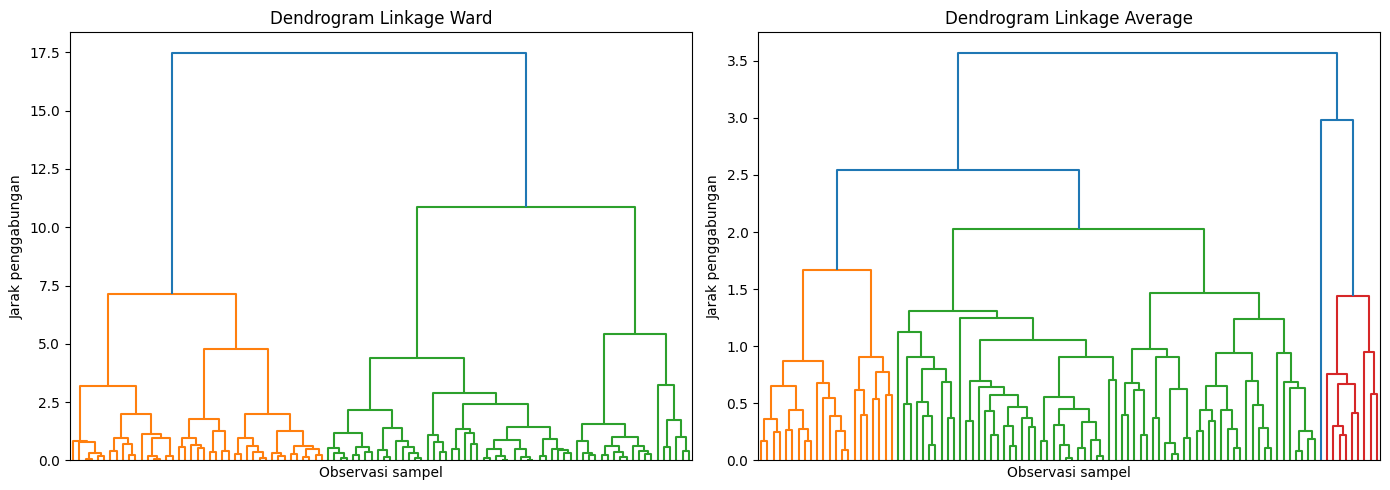

In [29]:

# PERBANDINGAN LINKAGE WARD DAN AVERAGE
# MENGGUNAKAN SAMPEL YANG SAMA


from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Ambil sampel yang sama seperti dendrogram sebelumnya
X_sample = X_scaled[sample_positions]

linkage_results = []
linkage_models = {}

for method in ["ward", "average"]:

    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = model.fit_predict(X_sample)

    sil = silhouette_score(X_sample, labels)
    dbi = davies_bouldin_score(X_sample, labels)

    linkage_results.append({
        "Linkage": method,
        "Jumlah Cluster": 3,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    })

    linkage_models[method] = model

# Tampilkan hasil perbandingan
comparison_linkage = pd.DataFrame(linkage_results)
display(comparison_linkage.round(4))

# VISUALISASI DENDROGRAM

Z_ward = linkage(X_sample, method="ward")
Z_average = linkage(X_sample, method="average")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dendrogram(Z_ward, no_labels=True, ax=axes[0])
axes[0].set_title("Dendrogram Linkage Ward")
axes[0].set_xlabel("Observasi sampel")
axes[0].set_ylabel("Jarak penggabungan")

dendrogram(Z_average, no_labels=True, ax=axes[1])
axes[1].set_title("Dendrogram Linkage Average")
axes[1].set_xlabel("Observasi sampel")
axes[1].set_ylabel("Jarak penggabungan")

plt.tight_layout()
plt.show()


Interpretasinya:
- Ward memiliki Silhouette Score lebih tinggi, artinya pemisahan cluster sedikit lebih baik berdasarkan metrik Silhouette.
- Average memiliki Davies–Bouldin Index lebih rendah, artinya kualitas pemisahan dan kekompakan cluster lebih baik menurut metrik tersebut.
Jadi, hasilnya tidak menunjukkan satu metode yang unggul pada semua metrik. Ward unggul pada Silhouette, sedangkan Average unggul pada Davies–Bouldin.

2. Jelaskan apa yang ditampilkan oleh dendrogram dan mengapa tinggi penggabungan penting.



Dendrogram merupakan visualisasi yang menunjukkan proses penggabungan data secara bertahap dalam Hierarchical Clustering.

Setiap cabang menggambarkan hubungan penggabungan antarobservasi atau kelompok. Sumbu vertikal menunjukkan jarak penggabungan antarkelompok.

Tinggi penggabungan penting karena menunjukkan tingkat perbedaan antara kelompok yang digabungkan. Penggabungan pada jarak yang semakin tinggi menunjukkan bahwa kelompok yang digabungkan semakin berbeda.

Dendrogram pada praktikum ini dibuat menggunakan sampel sebanyak 100 pelanggan agar visualisasi lebih mudah dibaca dan tidak terlalu padat. Oleh karena itu, hasil visualisasi tidak sepenuhnya menggambarkan struktur seluruh pelanggan.

3. Bandingkan metrik Hierarchical Clustering dengan K-Means pada jumlah cluster yang sama.

In [30]:

# PERBANDINGAN K-MEANS DAN HIERARCHICAL
# k = 3, menggunakan seluruh data pelanggan
k = 3

kmeans_row = metrics_kmeans.loc[
    metrics_kmeans["k"] == k
].iloc[0]

hier_row = metrics_hier.loc[
    metrics_hier["k"] == k
].iloc[0]

comparison_model = pd.DataFrame({
    "Algoritma": ["K-Means", "Hierarchical Ward"],
    "Jumlah Cluster": [k, k],
    "Silhouette Score": [
        kmeans_row["silhouette"],
        hier_row["silhouette"]
    ],
    "Davies-Bouldin Index": [
        kmeans_row["davies_bouldin"],
        hier_row["davies_bouldin"]
    ]
})

display(comparison_model.round(6))


,Algoritma,Jumlah Cluster,Silhouette Score,Davies-Bouldin Index
0,K-Means,3,0.415654,0.824915
1,Hierarchical Ward,3,0.364925,0.855645


Interpretasinya:
- K-Means memiliki Silhouette Score lebih tinggi dibandingkan Hierarchical Ward.
- K-Means memiliki Davies–Bouldin Index lebih rendah dibandingkan Hierarchical Ward.
- Dengan demikian, K-Means memberikan hasil evaluasi yang lebih baik berdasarkan kedua metrik tersebut pada k = 3.

# **PRAKTIKUM 11 — Modeling: DBSCAN**

In [31]:
from sklearn.cluster import DBSCAN

dbscan_results = []
dbscan_models = {}
for eps in [0.3, 0.5, 0.7, 1.0, 1.3]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    # Silhouette dihitung hanya bila terdapat >=2 cluster non-noise
    non_noise = labels != -1
    sil = np.nan
    dbi = np.nan
    if len(set(labels[non_noise])) >= 2 and non_noise.sum() > 2:
        sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
        dbi = davies_bouldin_score(X_scaled[non_noise], labels[non_noise])
    dbscan_results.append({
        "eps": eps, "min_samples": 10, "n_clusters": n_clusters,
        "noise_pct": noise_pct, "silhouette_non_noise": sil,
        "davies_bouldin_non_noise": dbi
    })
    dbscan_models[eps] = model

metrics_dbscan = pd.DataFrame(dbscan_results)
display(metrics_dbscan)


,eps,min_samples,n_clusters,noise_pct,silhouette_non_noise,davies_bouldin_non_noise
0,0.3,10,4,6.523744,0.105474,1.930128
1,0.5,10,2,1.798064,0.330006,1.119618
2,0.7,10,1,0.576302,NaN,NaN
3,1.0,10,1,0.207469,NaN,NaN
4,1.3,10,1,0.069156,NaN,NaN


## Visualisasi hasil DBSCAN


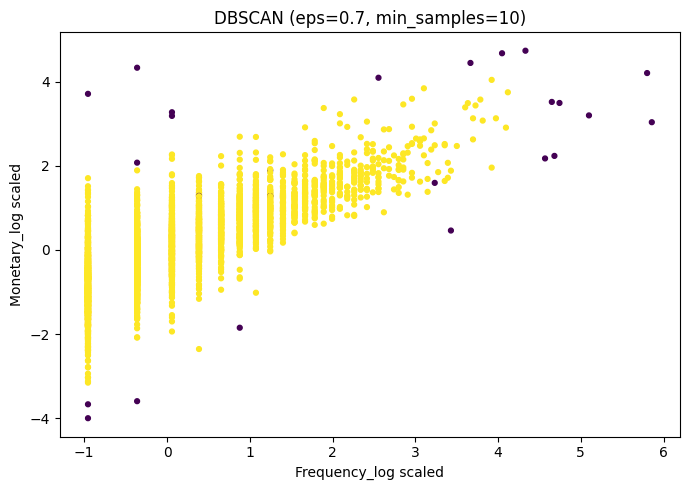

Cluster selain noise: 1
Persentase noise: 0.58 %


In [32]:
# Pilih eps untuk inspeksi; ganti berdasarkan tabel metrik dan tujuan
chosen_eps = 0.7
dbscan_model = dbscan_models[chosen_eps]
labels_db = dbscan_model.labels_

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 1], X_scaled[:, 2], c=labels_db, s=12)
plt.title(f"DBSCAN (eps={chosen_eps}, min_samples=10)")
plt.xlabel("Frequency_log scaled")
plt.ylabel("Monetary_log scaled")
plt.tight_layout(); plt.show()

print("Cluster selain noise:", len(set(labels_db)) - (1 if -1 in labels_db else 0))
print("Persentase noise:", round((labels_db == -1).mean()*100, 2), "%")


## Tugas

1. Jelaskan pengaruh eps terhadap jumlah cluster dan persentase noise.

Parameter eps menentukan jarak maksimum antar-data agar dianggap berada dalam satu lingkungan (neighborhood). Berdasarkan hasil percobaan, semakin besar nilai eps, jumlah cluster cenderung berkurang dan persentase noise juga menurun.

contoh
Eps 0.3	Jumlah cluster 4	Noise (%) 6.52%

Eps 0.7 Jumlah cluster	1	Noise (%) 0.58%
Pada eps = 0.3, terbentuk empat cluster dengan noise sebesar 6,52%. Sementara itu, pada eps = 0.7, hanya terbentuk satu cluster dengan noise sebesar 0,58%. Hal ini menunjukkan bahwa ketika nilai eps semakin besar, semakin banyak data yang dianggap saling berdekatan sehingga beberapa cluster dapat bergabung.



2. Mengapa silhouette DBSCAN harus ditafsirkan hati-hati ketika ada noise?

Silhouette Score pada DBSCAN perlu ditafsirkan secara hati-hati karena DBSCAN memiliki label khusus -1 untuk data yang dianggap noise.

Dalam perhitungan yang dilakukan pada praktikum ini, Silhouette Score hanya dihitung menggunakan data yang bukan noise. Akibatnya, penilaian tersebut tidak sepenuhnya menggambarkan seluruh data karena sebagian data tidak ikut diperhitungkan.

Selain itu, jika DBSCAN hanya menghasilkan satu cluster, Silhouette Score dan Davies–Bouldin Index tidak dapat dihitung karena kedua metrik tersebut membutuhkan minimal dua cluster.

Contohnya pada hasil percobaan ini: ketika eps = 0.7, DBSCAN hanya menghasilkan satu cluster sehingga nilai Silhouette dan Davies–Bouldin menjadi NaN.

3. Bandingkan DBSCAN dengan K-Means: asumsi cluster seperti apa yang ditangani masing-masing?


In [33]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import numpy as np

# Hasil K-Means dengan 3 cluster
labels_kmeans = kmeans_model.labels_

# Hasil DBSCAN dengan eps = 0.7
labels_dbscan = dbscan_models[0.7].labels_

# Fungsi menghitung metrik
def evaluate_clustering(X, labels, algorithm):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100

    non_noise = labels != -1
    sil = np.nan
    dbi = np.nan

    if len(set(labels[non_noise])) >= 2:
        sil = silhouette_score(X[non_noise], labels[non_noise])
        dbi = davies_bouldin_score(X[non_noise], labels[non_noise])

    return {
        "Algoritma": algorithm,
        "Jumlah Cluster": n_clusters,
        "Noise (%)": round(noise_pct, 2),
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    }

# Membuat tabel perbandingan
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, labels_kmeans, "K-Means (k=3)"),
    evaluate_clustering(X_scaled, labels_dbscan, "DBSCAN (eps=0.7)")
])

display(comparison)

,Algoritma,Jumlah Cluster,Noise (%),Silhouette Score,Davies-Bouldin Index
0,K-Means (k=3),3,0.00,0.415654,0.824915
1,DBSCAN (eps=0.7),1,0.58,NaN,NaN


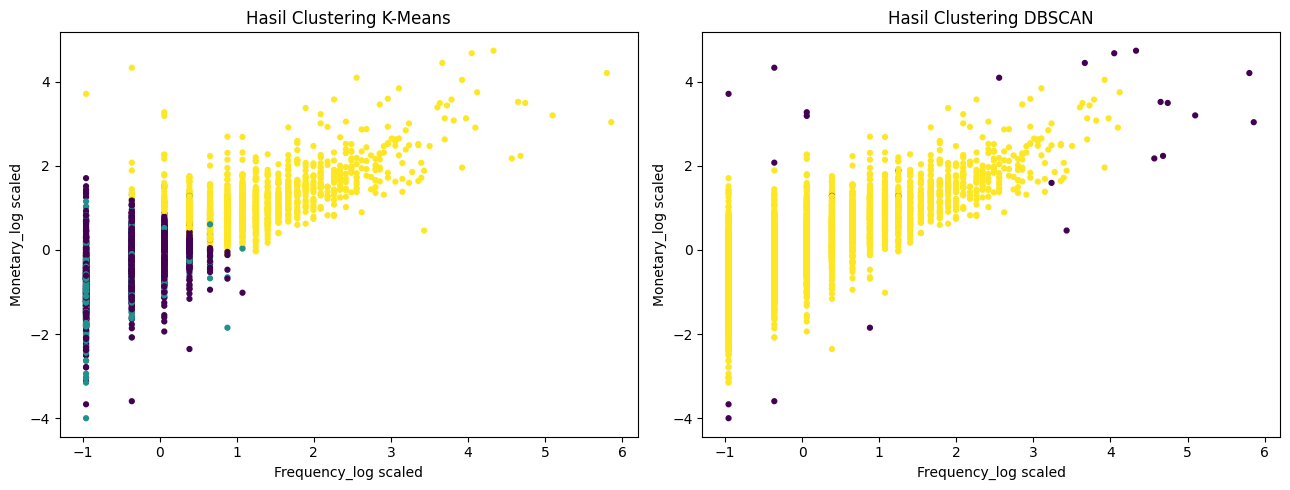

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Visualisasi K-Means
axes[0].scatter(
    X_scaled[:, 1],
    X_scaled[:, 2],
    c=labels_kmeans,
    cmap="viridis",
    s=12
)
axes[0].set_title("Hasil Clustering K-Means")
axes[0].set_xlabel("Frequency_log scaled")
axes[0].set_ylabel("Monetary_log scaled")

# Visualisasi DBSCAN
axes[1].scatter(
    X_scaled[:, 1],
    X_scaled[:, 2],
    c=labels_dbscan,
    cmap="viridis",
    s=12
)
axes[1].set_title("Hasil Clustering DBSCAN")
axes[1].set_xlabel("Frequency_log scaled")
axes[1].set_ylabel("Monetary_log scaled")

plt.tight_layout()
plt.show()

perbandingan K-Means dan DBSCAN

K-Means dan DBSCAN memiliki pendekatan yang berbeda dalam melakukan clustering. K-Means mengelompokkan pelanggan berdasarkan jarak terhadap titik pusat cluster (centroid), sedangkan DBSCAN mengelompokkan pelanggan berdasarkan kepadatan data di sekitarnya.

Pada percobaan ini, K-Means menggunakan tiga cluster, sedangkan DBSCAN menggunakan parameter eps = 0.7 dan min_samples = 10. Hasil DBSCAN menunjukkan satu cluster dengan noise sebesar 0,58%.

K-Means mengharuskan jumlah cluster ditentukan terlebih dahulu, sedangkan DBSCAN dapat menentukan jumlah cluster berdasarkan kepadatan data dan mampu mengidentifikasi data noise.

Kesimpulan: K-Means menghasilkan tiga kelompok pelanggan, sedangkan DBSCAN pada konfigurasi yang digunakan hanya menghasilkan satu kelompok utama. Oleh karena itu, K-Means sementara lebih sesuai untuk tujuan segmentasi pelanggan pada konfigurasi percobaan ini.

4. Apakah noise selalu berarti data salah? Jelaskan.


Tidak. Noise tidak selalu berarti data salah atau mengalami kerusakan. Dalam DBSCAN, noise merupakan data yang tidak memenuhi kriteria kepadatan untuk dimasukkan ke dalam cluster tertentu.

Noise dapat menunjukkan pelanggan dengan pola transaksi yang jarang, perilaku pembelian yang berbeda dari pelanggan lainnya, atau pelanggan dengan karakteristik khusus.

Oleh karena itu, data noise tidak boleh langsung dihapus. Data tersebut perlu diperiksa terlebih dahulu agar tidak menghilangkan informasi penting mengenai perilaku pelanggan.

# **PRAKTIKUM 12 — Evaluation: Membandingkan Mode**

In [35]:
# Contoh tabel perbandingan hasil K-Means dan Hierarchical
comparison = []

# K-Means: gunakan model yang dipilih pada Praktikum 8
labels = kmeans_model.labels_
comparison.append({
    "algorithm": "K-Means",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Hierarchical: contoh gunakan jumlah cluster terbaik sementara berdasarkan silhouette
best_hier_k = int(metrics_hier.loc[metrics_hier["silhouette"].idxmax(), "k"])
hier_model = hier_models[best_hier_k]
labels = hier_model.labels_
comparison.append({
    "algorithm": "Hierarchical-Ward",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Tambahkan K-Medoids bila instalasi berhasil dan DBSCAN sesuai hasil
comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("silhouette", ascending=False))


,algorithm,n_clusters,silhouette,davies_bouldin,noise_pct
0,K-Means,3,0.415654,0.824915,0.0
1,Hierarchical-Ward,2,0.382603,0.956354,0.0


## Membangun tabel profil cluster

In [36]:
# Contoh profil K-Means pada satu tabel RFM
rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    recency_mean=("Recency", "mean"),
    frequency_mean=("Frequency", "mean"),
    monetary_mean=("Monetary", "mean")
).round(2)
rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)
display(rfm_profile)


,jumlah_pelanggan,recency_median,frequency_median,monetary_median,recency_mean,frequency_mean,monetary_mean,persen_pelanggan
KMeans_Cluster,,,,,,,,
0,2038,46.0,2.0,508.80,55.31,2.05,612.67,46.98
1,980,253.0,1.0,290.46,255.70,1.39,397.03,22.59
2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,30.43


## Tugas

Buat tabel perbandingan semua algoritma yang berhasil dijalankan. Jika suatu algoritma gagal karena kompatibilitas paket atau keterbatasan komputasi, laporkan penyebab dan gunakan hasil eksperimen sampel sebagai pembanding yang diberi label jelas.

In [37]:
# Membuat tabel perbandingan semua algoritma

comparison_all = []

# 1. K-Means
labels_kmeans = kmeans_model.labels_

comparison_all.append({
    "Algoritma": "K-Means",
    "Parameter": f"k={best_k}",
    "Jumlah Cluster": len(set(labels_kmeans)),
    "Noise (%)": 0.0,
    "Silhouette": silhouette_score(X_scaled, labels_kmeans),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, labels_kmeans)
})


# 2. K-Medoids
best_kmedoids = int(
    metrics_kmedoids.loc[
        metrics_kmedoids["silhouette"].idxmax(), "k"
    ]
)

model_kmedoids = kmedoids_models[best_kmedoids]
labels_kmedoids = model_kmedoids.labels_

comparison_all.append({
    "Algoritma": "K-Medoids",
    "Parameter": f"k={best_kmedoids}",
    "Jumlah Cluster": len(set(labels_kmedoids)),
    "Noise (%)": 0.0,
    "Silhouette": silhouette_score(X_scaled, labels_kmedoids),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, labels_kmedoids)
})


# 3. Hierarchical Ward
best_hier_k = int(
    metrics_hier.loc[
        metrics_hier["silhouette"].idxmax(), "k"
    ]
)

hier_model = hier_models[best_hier_k]
labels_hier = hier_model.labels_

comparison_all.append({
    "Algoritma": "Hierarchical-Ward",
    "Parameter": f"k={best_hier_k}",
    "Jumlah Cluster": len(set(labels_hier)),
    "Noise (%)": 0.0,
    "Silhouette": silhouette_score(X_scaled, labels_hier),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, labels_hier)
})


# 4. DBSCAN
chosen_eps = 0.5
dbscan_model = dbscan_models[chosen_eps]
labels_dbscan = dbscan_model.labels_

non_noise = labels_dbscan != -1
n_clusters_dbscan = len(set(labels_dbscan)) - (
    1 if -1 in labels_dbscan else 0
)

sil_db = np.nan
dbi_db = np.nan

if n_clusters_dbscan >= 2 and non_noise.sum() > 2:
    sil_db = silhouette_score(
        X_scaled[non_noise],
        labels_dbscan[non_noise]
    )
    dbi_db = davies_bouldin_score(
        X_scaled[non_noise],
        labels_dbscan[non_noise]
    )

comparison_all.append({
    "Algoritma": "DBSCAN",
    "Parameter": f"eps={chosen_eps}, min_samples=10",
    "Jumlah Cluster": n_clusters_dbscan,
    "Noise (%)": round((~non_noise).mean() * 100, 2),
    "Silhouette": sil_db,
    "Davies-Bouldin": dbi_db
})


# Menampilkan tabel
comparison_all_df = pd.DataFrame(comparison_all)

display(
    comparison_all_df.sort_values(
        "Silhouette",
        ascending=False,
        na_position="last"
    ).round(4)
)

,Algoritma,Parameter,Jumlah Cluster,Noise (%),Silhouette,Davies-Bouldin
0,K-Means,k=3,3,0.0,0.4157,0.8249
1,K-Medoids,k=3,3,0.0,0.4139,0.8256
2,Hierarchical-Ward,k=2,2,0.0,0.3826,0.9564
3,DBSCAN,"eps=0.5, min_samples=10",2,1.8,0.3300,1.1196


### Interpretasi Hasil Perbandingan Algoritma Clustering

Berdasarkan hasil evaluasi terhadap empat algoritma clustering, yaitu K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN, diperoleh hasil bahwa K-Means memiliki performa terbaik berdasarkan metrik Silhouette Score dan Davies-Bouldin Index.

K-Means menghasilkan Silhouette Score sebesar 0,4157 dan Davies-Bouldin Index sebesar 0,8249 dengan jumlah tiga cluster. K-Medoids menghasilkan nilai yang hampir sama, yaitu Silhouette Score sebesar 0,4139 dan Davies-Bouldin Index sebesar 0,8256. Hal ini menunjukkan bahwa kualitas pengelompokan kedua algoritma relatif serupa.

Sementara itu, Hierarchical-Ward menghasilkan dua cluster dengan Silhouette Score sebesar 0,3826 dan Davies-Bouldin Index sebesar 0,9564. DBSCAN dengan parameter eps 0,5 dan min_samples 10 menghasilkan dua cluster serta noise sebesar 1,8%, dengan Silhouette Score sebesar 0,3300 dan Davies-Bouldin Index sebesar 1,1196.

Dari hasil tersebut, K-Means dipilih sebagai kandidat model terbaik sementara karena memiliki nilai Silhouette tertinggi dan Davies-Bouldin terendah. Selain itu, K-Means menghasilkan tiga kelompok pelanggan yang dapat dianalisis lebih lanjut berdasarkan karakteristik Recency, Frequency, dan Monetary.

Meskipun demikian, pemilihan model tidak hanya didasarkan pada nilai metrik. Ukuran setiap cluster, karakteristik pelanggan, kemudahan interpretasi, dan kemungkinan penerapan strategi bisnis juga perlu dipertimbangkan sebelum menentukan model akhir.

# **PRAKTIKUM 13 — Evaluation Iteratif dan Profil Cluster**

## Menampilkan kembali profil setiap cluster

In [38]:
# Profil pelanggan berdasarkan hasil K-Means

rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median")
).round(2)

rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)

display(rfm_profile)

,jumlah_pelanggan,recency_median,frequency_median,monetary_median,persen_pelanggan
KMeans_Cluster,,,,,
0,2038,46.0,2.0,508.80,46.98
1,980,253.0,1.0,290.46,22.59
2,1320,18.0,7.0,2570.50,30.43


Model kandidat yang kita pilih: K-Means dengan k=3.

Alasannya:
- Memiliki Silhouette Score tertinggi.
- Memiliki Davies-Bouldin Index terendah.
- Menghasilkan tiga kelompok pelanggan yang bisa dianalisis.

## Membuat profil setiap cluster

In [39]:
# Membuat profil cluster berdasarkan RFM asli

rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median")
).round(2)

# Menghitung persentase pelanggan
rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)

# Menampilkan profil cluster
display(rfm_profile)

,jumlah_pelanggan,recency_median,frequency_median,monetary_median,persen_pelanggan
KMeans_Cluster,,,,,
0,2038,46.0,2.0,508.80,46.98
1,980,253.0,1.0,290.46,22.59
2,1320,18.0,7.0,2570.50,30.43


Interpretasi
- Cluster 0: pelanggan cukup aktif, tetapi frekuensi dan nilai pembeliannya relatif rendah hingga menengah.
- Cluster 1: pelanggan sudah lama tidak bertransaksi, frekuensi pembelian rendah, dan nilai pembelian juga rendah.
- Cluster 2: pelanggan aktif, sering bertransaksi, dan memiliki nilai pembelian tinggi.

## Visualisasi profil cluster

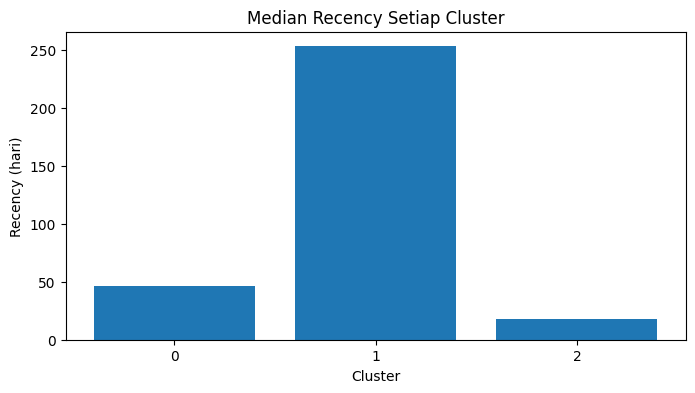

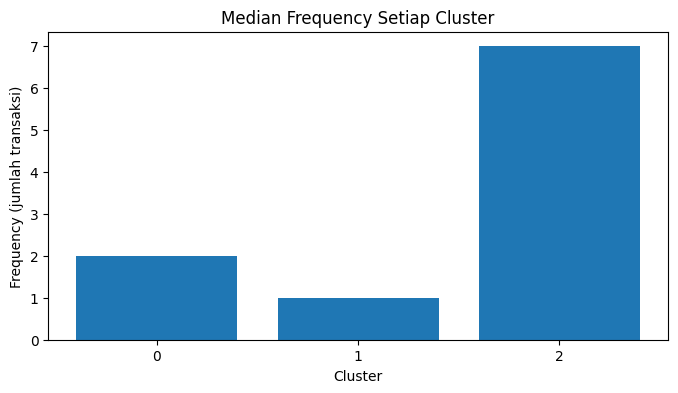

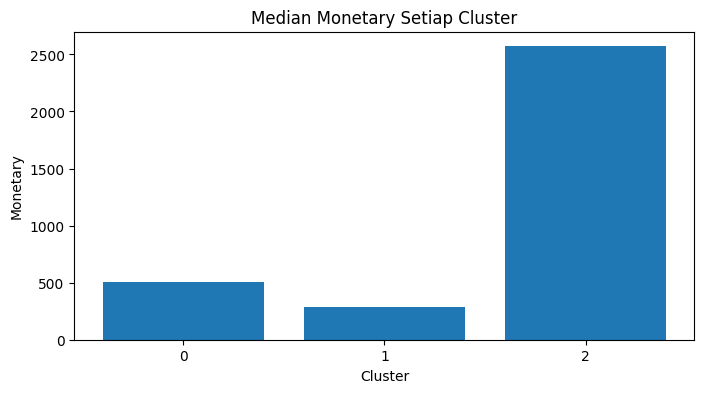

In [40]:
import matplotlib.pyplot as plt

# Visualisasi median Recency
plt.figure(figsize=(8, 4))
plt.bar(
    rfm_profile.index.astype(str),
    rfm_profile["recency_median"]
)
plt.title("Median Recency Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Recency (hari)")
plt.show()


# Visualisasi median Frequency
plt.figure(figsize=(8, 4))
plt.bar(
    rfm_profile.index.astype(str),
    rfm_profile["frequency_median"]
)
plt.title("Median Frequency Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Frequency (jumlah transaksi)")
plt.show()


# Visualisasi median Monetary
plt.figure(figsize=(8, 4))
plt.bar(
    rfm_profile.index.astype(str),
    rfm_profile["monetary_median"]
)
plt.title("Median Monetary Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Monetary")
plt.show()

Cara membaca grafik:

- Grafik Recency: cluster dengan angka paling kecil merupakan kelompok yang paling baru melakukan transaksi.
- Grafik Frequency: cluster dengan angka paling tinggi merupakan kelompok yang paling sering bertransaksi.
- Grafik Monetary: cluster dengan angka paling tinggi merupakan kelompok dengan nilai pembelian terbesar.

## Interpretasi dan rekomendasi setiap cluster

Interpretasi Cluster 0

Cluster 0 terdiri dari 2.038 pelanggan dengan median Recency 46 hari, Frequency 2 transaksi, dan Monetary 508,80. Hal ini menunjukkan bahwa pelanggan dalam kelompok ini masih cukup aktif melakukan pembelian, tetapi frekuensi dan nilai transaksinya relatif lebih rendah dibandingkan cluster 2.

Interpretasi Cluster 1

Cluster 1 terdiri dari 980 pelanggan dengan median Recency 253 hari, Frequency 1 transaksi, dan Monetary 290,46. Kelompok ini menunjukkan pelanggan yang sudah cukup lama tidak melakukan transaksi dan memiliki aktivitas pembelian rendah. Strategi yang dapat dilakukan adalah kampanye reaktivasi pelanggan.

Interpretasi Cluster 2

Cluster 2 terdiri dari 1.320 pelanggan dengan median Recency 18 hari, Frequency 7 transaksi, dan Monetary 2.570,50. Kelompok ini menunjukkan pelanggan yang aktif, sering melakukan pembelian, dan memiliki nilai transaksi relatif tinggi. Strategi yang dapat dilakukan adalah memberikan program loyalitas dan apresiasi pelanggan.

## Analisis iterasi model

In [41]:
# Menampilkan perbandingan metrik seluruh algoritma

comparison = pd.DataFrame({
    "Algoritma": [
        "K-Means",
        "K-Medoids",
        "Hierarchical Ward",
        "DBSCAN"
    ],
    "Jumlah Cluster": [3, 3, 2, 2],
    "Noise (%)": [0, 0, 0, 1.80],
    "Silhouette": [0.4157, 0.4139, 0.3826, 0.3300],
    "Davies-Bouldin": [0.8249, 0.8256, 0.9564, 1.1196]
})

display(comparison)

,Algoritma,Jumlah Cluster,Noise (%),Silhouette,Davies-Bouldin
0,K-Means,3,0.0,0.4157,0.8249
1,K-Medoids,3,0.0,0.4139,0.8256
2,Hierarchical Ward,2,0.0,0.3826,0.9564
3,DBSCAN,2,1.8,0.3300,1.1196


Kesimpulan analisis iterasi:

Berdasarkan hasil pengujian, penggunaan transformasi log1p dan StandardScaler membantu mempersiapkan fitur RFM sebelum proses clustering. K-Means dengan tiga cluster menjadi kandidat model terbaik berdasarkan Silhouette Score dan Davies-Bouldin Index. Meskipun demikian, evaluasi tetap perlu mempertimbangkan interpretasi karakteristik pelanggan dan kegunaan setiap segmen dalam pengambilan keputusan bisnis.

## Tugas

Tulis memo evaluasi 1–2 halaman: model yang direkomendasikan, bukti teknis, profil cluster, rekomendasi, keterbatasan, dan eksperimen lanjutan.

# MEMO EVALUASI CLUSTERING PELANGGAN

## 1. Model yang Direkomendasikan

Berdasarkan hasil evaluasi empat algoritma clustering, K-Means dengan jumlah cluster sebanyak tiga dipilih sebagai model kandidat utama. Model ini memperoleh Silhouette Score sebesar 0,4157 dan Davies-Bouldin Index sebesar 0,8249. Hasil tersebut merupakan yang terbaik di antara model yang dibandingkan berdasarkan kedua metrik tersebut.

## 2. Profil dan Interpretasi Cluster

Hasil clustering K-Means membagi 4.338 pelanggan menjadi tiga kelompok.

- **Cluster 0:** terdiri dari 2.038 pelanggan. Kelompok ini memiliki median Recency 46 hari, Frequency 2 transaksi, dan Monetary 508,80. Pelanggan masih cukup aktif, tetapi frekuensi dan nilai pembeliannya relatif rendah hingga menengah.
- **Cluster 1:** terdiri dari 980 pelanggan. Kelompok ini memiliki median Recency 253 hari, Frequency 1 transaksi, dan Monetary 290,46. Kelompok ini menunjukkan aktivitas pembelian yang rendah dan sudah lama tidak melakukan transaksi.
- **Cluster 2:** terdiri dari 1.320 pelanggan. Kelompok ini memiliki median Recency 18 hari, Frequency 7 transaksi, dan Monetary 2.570,50. Kelompok ini merupakan pelanggan yang relatif aktif, sering melakukan transaksi, dan memiliki nilai pembelian tinggi.

## 3. Rekomendasi Bisnis

Berdasarkan karakteristik setiap kelompok, rekomendasi yang dapat diberikan adalah:

- Cluster 0: memberikan rekomendasi produk dan penawaran yang sesuai dengan riwayat pembelian.
- Cluster 1: melakukan kampanye reaktivasi untuk mendorong pelanggan kembali bertransaksi.
- Cluster 2: memberikan program loyalitas dan apresiasi untuk mempertahankan pelanggan bernilai tinggi.

## 4. Analisis dan Keterbatasan

K-Means dan K-Medoids menghasilkan nilai evaluasi yang relatif berdekatan. Hal ini menunjukkan bahwa keduanya memberikan hasil pemisahan yang hampir serupa pada fitur yang digunakan. DBSCAN menghasilkan noise sekitar 1,8% pada parameter eps 0,5. Sementara itu, Hierarchical Ward menghasilkan dua cluster pada konfigurasi dengan Silhouette Score tertinggi.

Penelitian ini memiliki beberapa keterbatasan. Pertama, data yang digunakan merupakan data transaksi historis sehingga belum tentu menggambarkan perilaku pelanggan pada masa mendatang. Kedua, nilai Monetary dihitung dari transaksi positif setelah proses pembersihan dan tidak merepresentasikan pendapatan akuntansi bersih. Ketiga, penilaian model menggunakan metrik internal sehingga tetap membutuhkan interpretasi bisnis.

## 5. Eksperimen Lanjutan

Eksperimen selanjutnya dapat dilakukan dengan menguji kombinasi fitur RFM yang berbeda, membandingkan hasil clustering pada periode waktu yang berbeda, serta mengevaluasi stabilitas cluster. Hasil segmentasi juga perlu diperiksa secara berkala agar rekomendasi bisnis tetap sesuai dengan perubahan perilaku pelanggan.

## 6. Kesimpulan

Berdasarkan hasil evaluasi, K-Means dengan tiga cluster menjadi model kandidat utama untuk segmentasi pelanggan Online Retail. Model menghasilkan tiga kelompok dengan karakteristik RFM yang berbeda sehingga dapat digunakan sebagai dasar penyusunan strategi pemasaran yang lebih terarah.

# **PRAKTIKUM 14 — Deployment: Komunikasi Hasil**

In [42]:
# Memeriksa variabel yang dibutuhkan

required_variables = [
    "df", "clean", "rfm", "features",
    "X_scaled", "metrics_kmeans"
]

for var in required_variables:
    print(var, ":", "Tersedia" if var in globals() else "Belum tersedia")

df : Tersedia
clean : Tersedia
rfm : Tersedia
features : Tersedia
X_scaled : Tersedia
metrics_kmeans : Tersedia


## Membuat enam visualisasi minimum

### Visualisasi 1 — Grafik tren transaksi per bulan

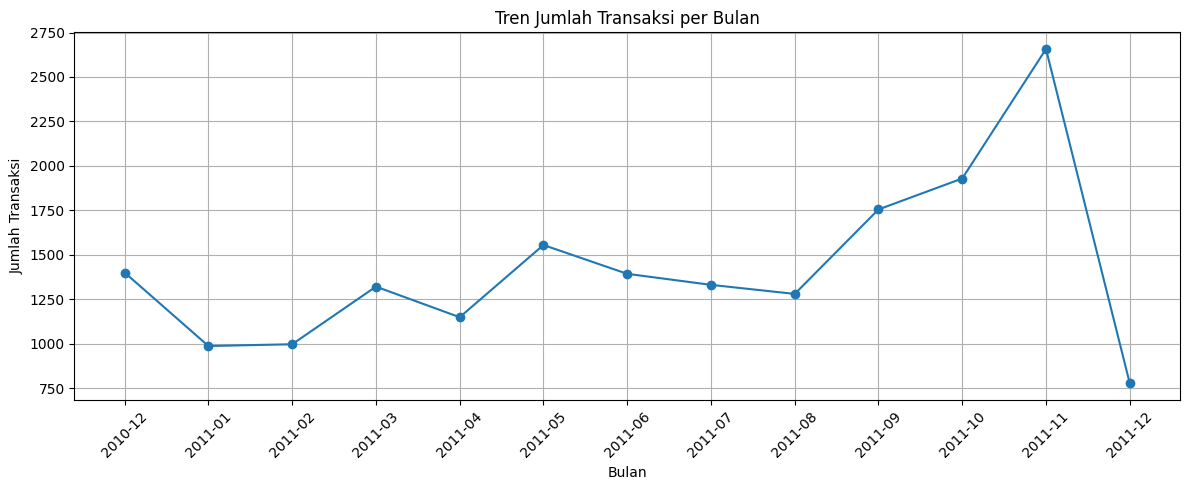

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengelompokkan transaksi berdasarkan bulan
monthly_transactions = (
    clean.groupby(clean["InvoiceDate"].dt.to_period("M"))["InvoiceNo"]
    .nunique()
)

# Membuat grafik
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_transactions.index.astype(str),
    monthly_transactions.values,
    marker="o"
)

plt.title("Tren Jumlah Transaksi per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Grafik tren transaksi per bulan digunakan untuk mengetahui perubahan aktivitas transaksi pelanggan selama periode pengamatan. Peningkatan jumlah transaksi menunjukkan aktivitas pembelian yang lebih tinggi, sedangkan penurunan menunjukkan berkurangnya aktivitas transaksi pada bulan tertentu.

### Visualisasi 2 — Distribusi atau boxplot fitur penting

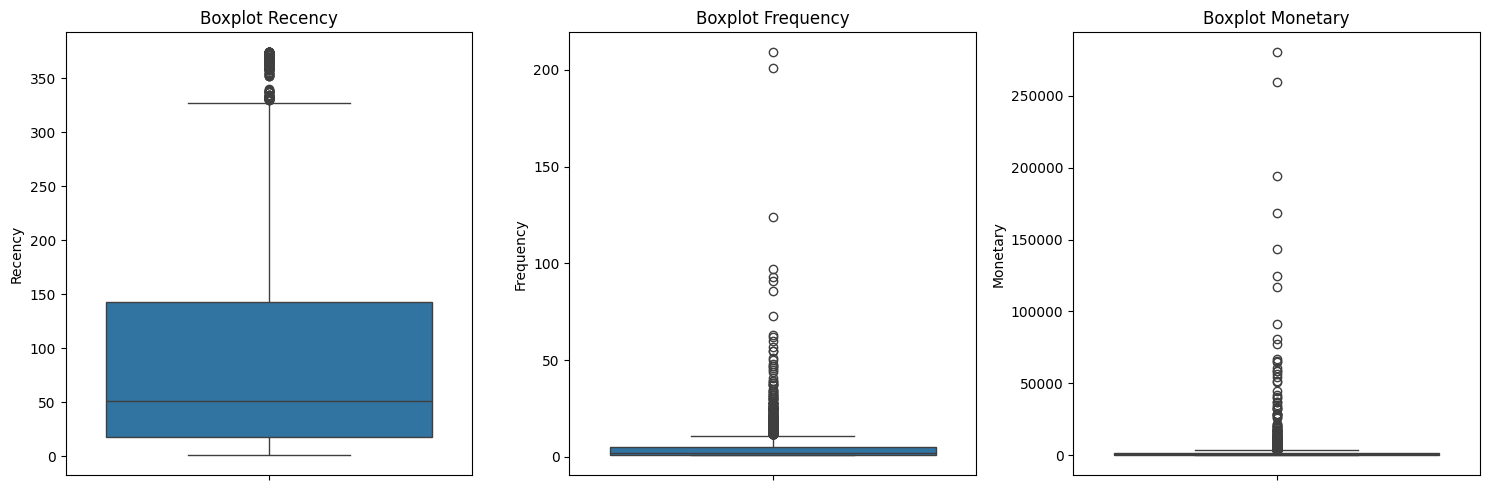

In [44]:
# Membuat visualisasi boxplot RFM

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=rfm["Recency"], ax=axes[0])
axes[0].set_title("Boxplot Recency")

sns.boxplot(y=rfm["Frequency"], ax=axes[1])
axes[1].set_title("Boxplot Frequency")

sns.boxplot(y=rfm["Monetary"], ax=axes[2])
axes[2].set_title("Boxplot Monetary")

plt.tight_layout()
plt.show()

Boxplot digunakan untuk melihat persebaran data dan mendeteksi nilai ekstrem pada fitur RFM. Fitur Frequency dan Monetary dapat memiliki distribusi yang menceng ke kanan karena terdapat pelanggan dengan frekuensi maupun nilai transaksi yang jauh lebih tinggi dibandingkan pelanggan lainnya.

### Visualisasi 3 — Elbow plot K-Means

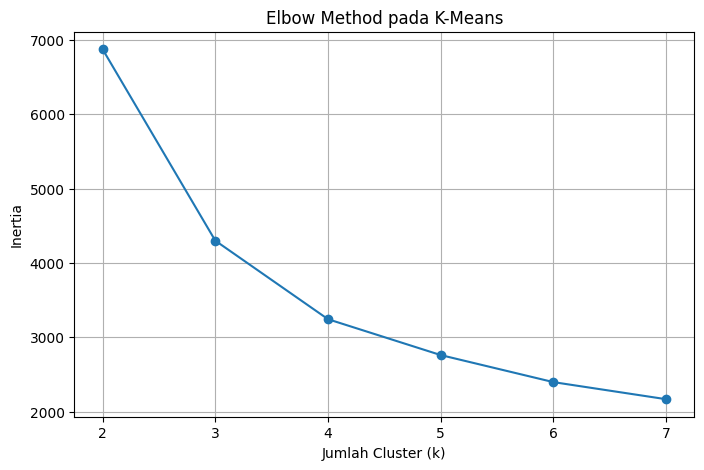

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    metrics_kmeans["k"],
    metrics_kmeans["inertia"],
    marker="o"
)

plt.title("Elbow Method pada K-Means")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(metrics_kmeans["k"])
plt.grid(True)
plt.show()

Elbow Method digunakan untuk membantu menentukan jumlah cluster yang sesuai berdasarkan perubahan nilai inertia. Semakin banyak cluster, nilai inertia cenderung semakin kecil. Pemilihan jumlah cluster perlu mempertimbangkan titik ketika penurunan inertia mulai melambat serta hasil metrik evaluasi lainnya.

Dalam penelitian ini, K-Means dengan k=3 dipilih sebagai kandidat utama berdasarkan hasil evaluasi sebelumnya.

### Visualisasi 4 — Grafik perbandingan metrik antarmodel

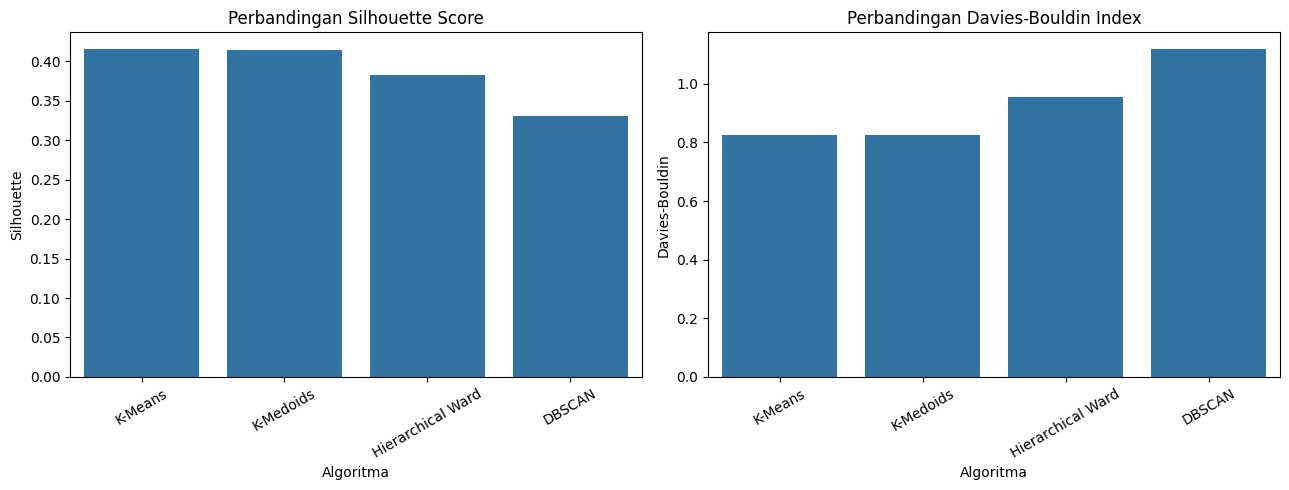

In [46]:
# Membuat tabel perbandingan jika belum tersedia

comparison = pd.DataFrame({
    "Algoritma": [
        "K-Means",
        "K-Medoids",
        "Hierarchical Ward",
        "DBSCAN"
    ],
    "Silhouette": [
        0.4157, 0.4139, 0.3826, 0.3300
    ],
    "Davies-Bouldin": [
        0.8249, 0.8256, 0.9564, 1.1196
    ]
})

# Grafik perbandingan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=comparison,
    x="Algoritma",
    y="Silhouette",
    ax=axes[0]
)
axes[0].set_title("Perbandingan Silhouette Score")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=comparison,
    x="Algoritma",
    y="Davies-Bouldin",
    ax=axes[1]
)
axes[1].set_title("Perbandingan Davies-Bouldin Index")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Berdasarkan hasil perbandingan, K-Means memiliki Silhouette Score tertinggi sebesar 0,4157 dan Davies-Bouldin Index terendah sebesar 0,8249. Dengan demikian, K-Means menjadi kandidat model utama dalam penelitian ini.

Catatan penting: nilai DBSCAN dihitung pada pelanggan non-noise, sedangkan model lainnya menggunakan seluruh data. Karena itu, perbandingan DBSCAN perlu dibaca dengan mempertimbangkan perbedaan tersebut. Jumlah cluster Hierarchical juga berbeda dari K-Means dan K-Medoids.

### Visualisasi 5 — Tabel profil cluster berbasis median RFM

In [47]:
rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median")
).round(2)

rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)

display(rfm_profile)

,jumlah_pelanggan,recency_median,frequency_median,monetary_median,persen_pelanggan
KMeans_Cluster,,,,,
0,2038,46.0,2.0,508.80,46.98
1,980,253.0,1.0,290.46,22.59
2,1320,18.0,7.0,2570.50,30.43


Interpretasi: tabel ini digunakan untuk menjelaskan karakteristik setiap kelompok pelanggan berdasarkan nilai median Recency, Frequency, dan Monetary.

### Visualisasi 6 — Scatter plot dua fitur dengan label cluster

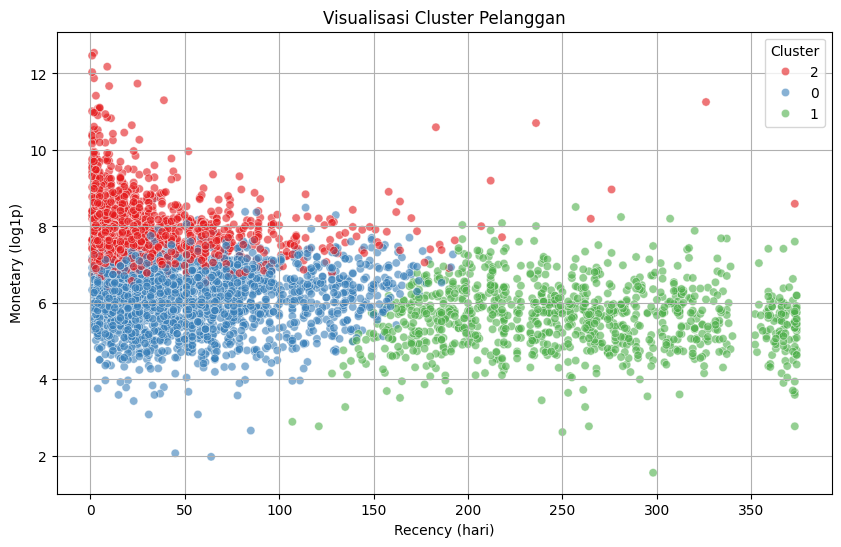

In [48]:
# Menggabungkan fitur dengan label cluster
plot_data = features.copy()

plot_data["Cluster"] = rfm.loc[
    plot_data.index, "KMeans_Cluster"
].astype(str)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_data,
    x="Recency",
    y="Monetary_log",
    hue="Cluster",
    palette="Set1",
    alpha=0.6
)

plt.title("Visualisasi Cluster Pelanggan")
plt.xlabel("Recency (hari)")
plt.ylabel("Monetary (log1p)")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

Scatter plot digunakan untuk memperlihatkan persebaran pelanggan berdasarkan dua fitur, yaitu Recency dan Monetary_log. Setiap warna menunjukkan kelompok pelanggan yang dihasilkan oleh K-Means.

Visualisasi ini hanya menggunakan dua dari tiga fitur RFM sehingga tidak sepenuhnya menggambarkan seluruh dimensi clustering.

### MENYIMPAN MODEL CLUSTERING MENGGUNAKAN JOBLIB

In [49]:
# Import library
import joblib
import os

# Membuat folder untuk menyimpan model
os.makedirs("deployment_model", exist_ok=True)

# Menyiapkan paket model dan preprocessing
deployment_package = {
    "model": kmeans_model,
    "scaler": scaler,
    "feature_columns": features.columns.tolist(),
    "algorithm": "K-Means",
    "best_k": best_k
}

# Menyimpan model dan scaler dalam satu file
joblib.dump(
    deployment_package,
    "deployment_model/clustering_deployment.joblib"
)

print("Model berhasil disimpan!")
print("Algoritma:", deployment_package["algorithm"])
print("Jumlah cluster:", deployment_package["best_k"])
print("Fitur:", deployment_package["feature_columns"])


Model berhasil disimpan!
Algoritma: K-Means
Jumlah cluster: 3
Fitur: ['Recency', 'Frequency_log', 'Monetary_log']


### MEMUAT MODEL YANG TELAH DISIMPAN

In [50]:
# Memuat model dari file Joblib
loaded_package = joblib.load(
    "deployment_model/clustering_deployment.joblib"
)

# Mengambil model dan scaler
loaded_model = loaded_package["model"]
loaded_scaler = loaded_package["scaler"]

# Mengambil informasi fitur
feature_columns = loaded_package["feature_columns"]

print("Model berhasil dimuat!")
print("Algoritma:", loaded_package["algorithm"])
print("Jumlah cluster:", loaded_package["best_k"])
print("Fitur model:", feature_columns)


Model berhasil dimuat!
Algoritma: K-Means
Jumlah cluster: 3
Fitur model: ['Recency', 'Frequency_log', 'Monetary_log']


### PREDIKSI CLUSTER PELANGGAN BARU

In [51]:
import pandas as pd
import numpy as np

# Data RFM pelanggan baru
data_baru = pd.DataFrame({
    "Recency": [15],
    "Frequency": [8],
    "Monetary": [2500000]
})

# Melakukan transformasi log sesuai Praktikum 7
data_baru["Frequency_log"] = np.log1p(
    data_baru["Frequency"]
)

data_baru["Monetary_log"] = np.log1p(
    data_baru["Monetary"]
)

# Mengambil fitur sesuai urutan saat training
data_baru_features = data_baru[feature_columns]

# Melakukan scaling menggunakan scaler lama
data_baru_scaled = loaded_scaler.transform(
    data_baru_features
)

# Melakukan prediksi cluster
hasil_prediksi = loaded_model.predict(
    data_baru_scaled
)

# Menampilkan hasil
data_baru["Cluster"] = hasil_prediksi

print("Data pelanggan baru:")
display(data_baru)

print("Hasil prediksi cluster:")
print("Pelanggan masuk ke Cluster:", hasil_prediksi[0])


Data pelanggan baru:


,Recency,Frequency,Monetary,Frequency_log,Monetary_log,Cluster
0,15,8,2500000,2.197225,14.731802,2


Hasil prediksi cluster:
Pelanggan masuk ke Cluster: 2


### PREDIKSI BEBERAPA PELANGGAN BARU

In [52]:
# Membuat data beberapa pelanggan baru
data_pelanggan = pd.DataFrame({
    "CustomerID": ["C001", "C002", "C003", "C004"],
    "Recency": [5, 120, 30, 200],
    "Frequency": [25, 2, 10, 1],
    "Monetary": [5000000, 150000, 1200000, 50000]
})

# Transformasi logaritmik
data_pelanggan["Frequency_log"] = np.log1p(
    data_pelanggan["Frequency"]
)

data_pelanggan["Monetary_log"] = np.log1p(
    data_pelanggan["Monetary"]
)

# Memilih fitur sesuai model
X_pelanggan_baru = data_pelanggan[feature_columns]

# Scaling menggunakan scaler hasil Praktikum 8
X_pelanggan_scaled = loaded_scaler.transform(
    X_pelanggan_baru
)

# Prediksi cluster menggunakan model yang telah di-load
data_pelanggan["Cluster"] = loaded_model.predict(
    X_pelanggan_scaled
)

# Menampilkan hasil prediksi
display(
    data_pelanggan[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Cluster"]
    ]
)


,CustomerID,Recency,Frequency,Monetary,Cluster
0,C001,5,25,5000000,2
1,C002,120,2,150000,2
2,C003,30,10,1200000,2
3,C004,200,1,50000,2


### MENGUNDUH FILE MODEL

In [53]:
from google.colab import files

files.download(
    "deployment_model/clustering_deployment.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
# Install streamlit dan pyngrok
!pip install streamlit pyngrok --quiet

### Segmentasi Pelanggan Online Retail

In [55]:
%%writefile app.py

import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Memuat model dan scaler
package = joblib.load("deployment_model/clustering_deployment.joblib")

model = package["model"]
scaler = package["scaler"]
feature_columns = package["feature_columns"]

# Keterangan cluster (dari profil RFM di Praktikum 13)
keterangan = {
    0: "Pelanggan cukup aktif, frekuensi dan nilai pembelian rendah-menengah. Rekomendasi: tawarkan produk sesuai riwayat pembelian.",
    1: "Pelanggan sudah lama tidak bertransaksi dan pembeliannya rendah. Rekomendasi: kampanye reaktivasi (voucher, pengingat).",
    2: "Pelanggan aktif, sering membeli, nilai pembelian tinggi. Rekomendasi: program loyalitas dan penawaran eksklusif.",
}

st.title("Segmentasi Pelanggan Online Retail")
st.write("Prediksi cluster pelanggan menggunakan K-Means berdasarkan RFM.")

recency = st.number_input("Recency (hari sejak transaksi terakhir)", min_value=0, value=15)
frequency = st.number_input("Frequency (jumlah transaksi)", min_value=1, value=8)
monetary = st.number_input("Monetary (total belanja, £)", min_value=1.0, value=2500.0)

if st.button("Prediksi Cluster"):
    data = pd.DataFrame({
        "Recency": [recency],
        "Frequency_log": [np.log1p(frequency)],
        "Monetary_log": [np.log1p(monetary)],
    })

    data_scaled = scaler.transform(data[feature_columns])
    cluster = int(model.predict(data_scaled)[0])

    st.success(f"Pelanggan masuk ke Cluster {cluster}")
    st.info(keterangan[cluster])

Writing app.py


In [56]:
!streamlit run app.py &>/content/streamlit.log &

In [57]:
import sklearn

isi = f"""streamlit
scikit-learn=={sklearn.__version__}
pandas
numpy
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(isi)

print(isi)

streamlit
scikit-learn==1.6.1
pandas
numpy
joblib



In [58]:
!pip install streamlit joblib scikit-learn pandas numpy

In [59]:
!zip -r deploy.zip app.py requirements.txt deployment_model

from google.colab import files
files.download("deploy.zip")

  adding: app.py (deflated 52%)
  adding: requirements.txt (stored 0%)
  adding: deployment_model/ (stored 0%)
  adding: deployment_model/clustering_deployment.joblib (deflated 85%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install streamlit joblib scikit-learn pandas numpy

!streamlit run app.py



2026-11-17 05:00:40.663 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.29.82.90:8502



# LAPORAN AKHIR PRAKTIKUM SAINS DATA
## CLUSTERING PELANGGAN ONLINE RETAIL MENGGUNAKAN PENDEKATAN CRISP-DM

## 1. Ringkasan Eksekutif

Penelitian ini bertujuan melakukan segmentasi pelanggan berdasarkan data transaksi Online Retail menggunakan metode clustering dengan pendekatan CRISP-DM. Dataset yang digunakan terdiri dari 541.909 baris transaksi dengan delapan atribut.

Setelah dilakukan proses pembersihan data, diperoleh 392.692 baris transaksi dan 4.338 pelanggan yang dapat dianalisis. Selanjutnya dilakukan pembentukan fitur RFM (Recency, Frequency, Monetary) sebagai dasar segmentasi pelanggan.

Empat algoritma clustering diterapkan, yaitu K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN. Berdasarkan hasil evaluasi, K-Means dengan tiga cluster menjadi kandidat model utama dengan Silhouette Score sebesar 0,4157 dan Davies-Bouldin Index sebesar 0,8249.

Hasil segmentasi membagi pelanggan menjadi tiga kelompok dengan karakteristik berbeda, yaitu pelanggan yang cukup aktif dengan nilai pembelian rendah hingga menengah, pelanggan dengan aktivitas pembelian rendah, serta pelanggan aktif dengan frekuensi dan nilai pembelian tinggi. Hasil tersebut dapat digunakan sebagai dasar penyusunan strategi pemasaran yang lebih terarah.

## 2. Business Understanding

### 2.1 Identifikasi Masalah

Perusahaan memiliki data transaksi pelanggan dalam jumlah besar. Namun, data tersebut belum secara langsung menunjukkan karakteristik dan perbedaan perilaku setiap pelanggan. Oleh karena itu, diperlukan proses segmentasi untuk mengelompokkan pelanggan berdasarkan pola transaksi.

### 2.2 Tujuan Analisis

Tujuan penelitian ini adalah:
1. Mengidentifikasi pola transaksi pelanggan.
2. Membentuk segmentasi pelanggan menggunakan fitur RFM.
3. Membandingkan hasil beberapa algoritma clustering.
4. Menentukan model kandidat terbaik berdasarkan evaluasi.
5. Menyusun rekomendasi berdasarkan karakteristik pelanggan.

### 2.3 Pertanyaan Analitik

1. Bagaimana karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary?
2. Bagaimana hasil pengelompokan pelanggan menggunakan algoritma clustering?
3. Algoritma mana yang memberikan hasil evaluasi terbaik?
4. Bagaimana rekomendasi strategi untuk setiap kelompok pelanggan?

### 2.4 Kriteria Keberhasilan

Keberhasilan analisis dinilai berdasarkan:
- Algoritma dapat menghasilkan kelompok pelanggan.
- Nilai Silhouette Score dan Davies-Bouldin Index dapat digunakan untuk mengevaluasi hasil.
- Setiap cluster memiliki karakteristik RFM yang dapat diinterpretasikan.
- Hasil segmentasi dapat diterjemahkan menjadi rekomendasi bisnis.

## 3. Data Understanding

### 3.1 Sumber Data

Dataset yang digunakan adalah Online Retail Dataset dari UCI Machine Learning Repository. Dataset berisi informasi transaksi penjualan suatu perusahaan ritel selama periode 1 Desember 2010 hingga 9 Desember 2011.

### 3.2 Kamus Data

| Atribut | Keterangan |
|---|---|
| InvoiceNo | Nomor faktur transaksi |
| StockCode | Kode produk |
| Description | Deskripsi produk |
| Quantity | Jumlah produk yang dibeli |
| InvoiceDate | Tanggal transaksi |
| UnitPrice | Harga satuan produk |
| CustomerID | Identitas pelanggan |
| Country | Negara pelanggan |

### 3.3 Kualitas Data

Hasil pemeriksaan awal menunjukkan:
- Jumlah data awal: 541.909 baris.
- Missing CustomerID: 135.080 data.
- Missing Description: 1.454 data.
- Duplikasi: 5.268 baris.
- Quantity tidak valid (kurang dari atau sama dengan nol): 10.624 baris.
- UnitPrice tidak valid (kurang dari atau sama dengan nol): 2.517 baris.
- Transaksi dengan InvoiceNo berawalan C: 9.288 baris.

### 3.4 Exploratory Data Analysis

EDA dilakukan untuk memahami karakteristik transaksi berdasarkan waktu, produk, pelanggan, dan negara. Analisis juga mencakup pemeriksaan distribusi data, nilai ekstrem, serta hubungan antarfitur.

Grafik tren transaksi per bulan digunakan untuk mengamati perubahan aktivitas transaksi selama periode pengamatan. Boxplot digunakan untuk melihat distribusi dan nilai ekstrem pada fitur penting.

## 4. Data Preparation

### 4.1 Pembersihan Data

Pembersihan dilakukan melalui beberapa tahapan:
1. Menghapus data duplikat.
2. Menghapus data yang tidak memiliki CustomerID.
3. Menghapus data dengan InvoiceDate tidak valid.
4. Mengeluarkan transaksi pembatalan yang memiliki InvoiceNo berawalan C.
5. Menghapus transaksi dengan Quantity dan UnitPrice kurang dari atau sama dengan nol.
6. Membentuk atribut LineValue dari perkalian Quantity dan UnitPrice.

Setelah pembersihan, diperoleh 392.692 baris transaksi dengan 4.338 pelanggan.

### 4.2 Pembentukan RFM

Fitur RFM dibentuk dengan tiga indikator:
- Recency: jarak hari antara tanggal acuan dan transaksi terakhir pelanggan.
- Frequency: jumlah faktur transaksi unik milik pelanggan.
- Monetary: total nilai transaksi pelanggan.

Tanggal acuan menggunakan satu hari setelah tanggal transaksi terakhir pada dataset, yaitu 10 Desember 2011.

### 4.3 Transformasi dan Scaling

Frequency dan Monetary mengalami transformasi log1p untuk mengurangi kemencengan distribusi. Selanjutnya, fitur Recency, Frequency_log, dan Monetary_log distandardisasi menggunakan StandardScaler agar memiliki skala yang sebanding dalam proses clustering.

## 5. Modeling

Penelitian menggunakan empat algoritma clustering.

### 5.1 K-Means

K-Means mengelompokkan pelanggan berdasarkan centroid. Pengujian dilakukan untuk jumlah cluster 2 sampai 7 menggunakan random_state=42 dan n_init=10. Berdasarkan evaluasi, k=3 dipilih sebagai kandidat utama.

### 5.2 K-Medoids

K-Medoids menggunakan anggota data aktual sebagai pusat cluster atau medoid. Pengujian dilakukan untuk k=2 sampai 7 dengan metric Euclidean, method alternate, dan inisialisasi k-medoids++.

### 5.3 Hierarchical Clustering

Hierarchical Clustering menggunakan pendekatan Agglomerative dengan linkage Ward. Pengujian dilakukan untuk jumlah cluster 2 sampai 7. Dendrogram digunakan untuk membantu memahami proses penggabungan cluster.

### 5.4 DBSCAN

DBSCAN mengelompokkan data berdasarkan kepadatan. Pengujian dilakukan menggunakan beberapa nilai eps, yaitu 0,3; 0,5; 0,7; 1,0; dan 1,3, dengan min_samples=10. Algoritma ini juga dapat mengidentifikasi data noise.

## 6. Evaluation

### 6.1 Perbandingan Model

| Algoritma | Jumlah Cluster | Noise | Silhouette | Davies-Bouldin |
|---|---:|---:|---:|---:|
| K-Means | 3 | 0% | 0,4157 | 0,8249 |
| K-Medoids | 3 | 0% | 0,4139 | 0,8256 |
| Hierarchical Ward | 2 | 0% | 0,3826 | 0,9564 |
| DBSCAN | 2 | 1,8% | 0,3300 | 1,1196 |

Metrik DBSCAN dihitung pada data non-noise. Oleh karena itu, hasilnya perlu diinterpretasikan dengan mempertimbangkan perbedaan perlakuan noise.

### 6.2 Profil Cluster K-Means

K-Means dengan tiga cluster menghasilkan profil berikut:

| Cluster | Jumlah Pelanggan | Median Recency | Median Frequency | Median Monetary |
|---|---:|---:|---:|---:|
| 0 | 2.038 | 46 | 2 | 508,80 |
| 1 | 980 | 253 | 1 | 290,46 |
| 2 | 1.320 | 18 | 7 | 2.570,50 |

Cluster 0 merupakan pelanggan yang cukup aktif dengan frekuensi dan nilai pembelian relatif rendah hingga menengah.

Cluster 1 merupakan pelanggan dengan aktivitas pembelian rendah dan sudah lama tidak melakukan transaksi.

Cluster 2 merupakan pelanggan yang relatif aktif, sering melakukan transaksi, dan memiliki nilai pembelian tinggi.

### 6.3 Pemilihan Model

K-Means dengan tiga cluster dipilih sebagai kandidat utama karena memiliki Silhouette Score tertinggi dan Davies-Bouldin Index terendah di antara konfigurasi model yang dibandingkan.

## 7. Deployment

### 7.1 Rekomendasi Strategi

- Cluster 0: memberikan rekomendasi produk dan penawaran yang sesuai dengan riwayat pembelian.
- Cluster 1: melakukan kampanye reaktivasi pelanggan.
- Cluster 2: memberikan program loyalitas dan apresiasi kepada pelanggan bernilai tinggi.

### 7.2 Indikator Pemantauan

Beberapa indikator yang dapat digunakan untuk memantau keberhasilan strategi adalah:
1. Perubahan jumlah transaksi pelanggan.
2. Perubahan nilai Frequency.
3. Perubahan nilai Monetary.
4. Jumlah pelanggan yang kembali melakukan transaksi.
5. Perubahan jumlah pelanggan pada setiap cluster.

### 7.3 Risiko dan Keterbatasan

Analisis menggunakan data historis sehingga belum tentu menggambarkan perilaku pelanggan pada masa mendatang. Nilai Monetary merupakan hasil agregasi transaksi positif setelah pembersihan, bukan pendapatan akuntansi bersih. Selain itu, perubahan perilaku pelanggan dapat menyebabkan karakteristik cluster berubah sehingga evaluasi perlu dilakukan secara berkala.

## 8. Reproducibility

Eksperimen dilakukan menggunakan Python pada Google Colab dengan library Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, dan Scikit-learn-Extra.

Parameter utama yang digunakan:
- Random seed: 42.
- Jumlah cluster K-Means: 3.
- Jumlah cluster K-Medoids: 3.
- Linkage Hierarchical: Ward.
- DBSCAN: eps=0,5 dan min_samples=10.
- Scaling: StandardScaler.
- Transformasi: log1p pada Frequency dan Monetary.

Tanggal acuan RFM: 10 Desember 2011.

Seluruh proses preprocessing, pembentukan fitur, pemodelan, dan evaluasi didokumentasikan dalam notebook Google Colab agar eksperimen dapat ditelusuri dan dijalankan kembali.

# **BAB 3. Template Notebook Praktikum**

## Kesimpulan


Berdasarkan hasil proses clustering pada dataset Online Retail, dapat disimpulkan bahwa segmentasi pelanggan menggunakan metode RFM (Recency, Frequency, dan Monetary) dapat membantu mengelompokkan pelanggan berdasarkan perilaku transaksi mereka.

Dataset awal memiliki 541.909 baris data. Setelah dilakukan pembersihan, jumlah data menjadi 392.692 baris dengan 4.338 pelanggan. Fitur RFM kemudian digunakan sebagai dasar proses clustering.

Dari empat algoritma yang diuji, yaitu K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN, K-Means dengan jumlah cluster sebanyak 3 menghasilkan nilai evaluasi terbaik pada perbandingan utama. Model tersebut memperoleh Silhouette Score sebesar 0,4157 dan Davies-Bouldin Index sebesar 0,8249.

Berdasarkan profil RFM aktual, tiga kelompok pelanggan yang terbentuk adalah:
1. Cluster 0: Memiliki Recency median 46 hari, Frequency median 2 transaksi, dan Monetary median 508,80. Kelompok ini merupakan pelanggan dengan aktivitas dan nilai transaksi relatif rendah hingga menengah.
2. Cluster 1: Memiliki Recency median 253 hari, Frequency median 1 transaksi, dan Monetary median 290,46. Kelompok ini merupakan pelanggan yang sudah cukup lama tidak melakukan transaksi dan memiliki aktivitas pembelian rendah.
3. Cluster 2: Memiliki Recency median 18 hari, Frequency median 7 transaksi, dan Monetary median 2.570,50. Kelompok ini merupakan pelanggan aktif dengan frekuensi dan nilai transaksi relatif tinggi.
Dengan demikian, hasil clustering dapat digunakan sebagai dasar penyusunan strategi pemasaran yang berbeda untuk setiap kelompok pelanggan.

Jawaban terhadap pertanyaan analitik: Apakah pelanggan dapat dikelompokkan berdasarkan perilaku pembeliannya? Ya. Hasil RFM dan K-Means menunjukkan adanya tiga kelompok pelanggan dengan karakteristik yang berbeda.

Rencana lanjutan: Perusahaan dapat menerapkan promosi yang disesuaikan dengan setiap kelompok pelanggan, memantau perubahan perilaku pembelian secara berkala, serta melakukan evaluasi ulang model ketika terdapat data transaksi terbaru.


## Checklist Reproduksibilitas

Checklist reproduksibilitas digunakan untuk memastikan bahwa seluruh tahapan pengolahan data dan pemodelan clustering dapat dilakukan kembali dengan prosedur yang sama.

| No. | Aspek Reproduksibilitas | Keterangan |
|---|---|---|
| 1 | Sumber Dataset | Dataset menggunakan Online Retail yang diperoleh dari UCI Machine Learning Repository. Tanggal pengunduhan 30 oktober 2026 |
| 2 | Aturan Pembersihan Data | Menghapus 5.268 data duplikat, data CustomerID kosong, InvoiceDate tidak valid, transaksi pembatalan (InvoiceNo diawali huruf C), serta data dengan Quantity dan UnitPrice kurang dari atau sama dengan 0. |
| 3 | Jumlah Data | Jumlah data awal sebanyak 541.909 baris dan setelah proses pembersihan menjadi 392.692 baris. |
| 4 | Tanggal Acuan Recency | Tanggal acuan yang digunakan adalah 10 Desember 2011, yaitu satu hari setelah tanggal transaksi terakhir. |
| 5 | Fitur Clustering | Fitur yang digunakan adalah Recency, Frequency, dan Monetary. Frequency dan Monetary ditransformasikan menggunakan log1p sebelum proses clustering. |
| 6 | Scaling Data | Proses scaling menggunakan StandardScaler. CustomerID tidak dimasukkan sebagai fitur clustering karena hanya digunakan sebagai identitas pelanggan. |
| 7 | Parameter dan Random State | K-Means menggunakan random_state = 42 dan n_init = 10. Parameter algoritma lainnya dicatat sesuai konfigurasi pada proses pemodelan. |
| 8 | Evaluasi Model | Evaluasi menggunakan Silhouette Score dan Davies-Bouldin Index berdasarkan data dan label hasil clustering masing-masing algoritma. |
| 9 | Pemetaan Label Cluster | Label cluster dipetakan kembali ke tabel RFM asli untuk mengetahui karakteristik pelanggan berdasarkan nilai Recency, Frequency, dan Monetary. |

**Kesimpulan Checklist:**

Berdasarkan checklist tersebut, proses clustering telah memiliki tahapan pengolahan data, pembentukan fitur, pemodelan, dan evaluasi yang terdokumentasi. Dokumentasi ini membantu memastikan proses analisis dapat ditelusuri dan direproduksi kembali.


In [ ]:

import sys
from importlib.metadata import version, PackageNotFoundError

print("Versi Python:", sys.version)

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scikit-learn-extra"
]

print("\nVersi Library:")
for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: Tidak ditemukan")


Versi Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Versi Library:
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1
scikit-learn-extra: 0.3.0


# **BAB 4. Rubrik Penilaian**

## Pertanyaan evaluasi akhir

1. Jelaskan perbedaan Business Understanding dan Data Understanding pada proyek ini.


Business Understanding merupakan tahap untuk memahami permasalahan bisnis dan tujuan analisis yang ingin dicapai. Pada proyek ini, tujuannya adalah mengelompokkan pelanggan berdasarkan perilaku transaksi agar perusahaan dapat menentukan strategi pemasaran yang sesuai.

Sementara itu, Data Understanding merupakan tahap untuk memahami dataset yang digunakan, termasuk struktur data, jenis atribut, jumlah data, nilai kosong, data duplikat, dan karakteristik transaksi.

2. Mengapa EDA harus dilakukan sebelum pembersihan data final?

EDA (Exploratory Data Analysis) perlu dilakukan untuk mengetahui kondisi awal dataset sebelum menentukan aturan pembersihan. Melalui EDA, kita dapat menemukan data kosong, duplikat, nilai tidak wajar, distribusi data, dan kemungkinan outlier. Dengan begitu, proses pembersihan dapat dilakukan berdasarkan kondisi data, bukan menghapus data secara sembarangan.

3. Mengapa transaksi tidak sama dengan pelanggan sebagai unit analisis?

Transaksi merupakan satu kejadian pembelian, sedangkan pelanggan merupakan individu atau pihak yang melakukan pembelian. Satu pelanggan dapat melakukan banyak transaksi. Oleh karena itu, jika tujuan analisis adalah segmentasi pelanggan, data transaksi perlu dikelompokkan berdasarkan CustomerID agar setiap pelanggan memiliki satu nilai RFM.

4. Jelaskan definisi Recency, Frequency, dan Monetary serta satu keterbatasan masing-masing.


- Recency: Mengukur jarak waktu dalam hari sejak terakhir pelanggan melakukan pembelian hingga tanggal acuan. Keterbatasannya, Recency tidak menunjukkan seberapa besar nilai pembelian pelanggan.



- Frequency: Mengukur jumlah transaksi unik yang dilakukan pelanggan. Keterbatasannya, Frequency tidak memperhitungkan jumlah barang dalam setiap transaksi.



- Monetary: Mengukur total nilai pembelian pelanggan. Keterbatasannya, Monetary dapat dipengaruhi oleh satu transaksi dengan nilai sangat besar sehingga tidak selalu menggambarkan kebiasaan pembelian secara umum.

5. Mengapa scaling penting untuk K-Means dan DBSCAN?

Scaling penting karena kedua algoritma tersebut menggunakan perhitungan jarak untuk menentukan kedekatan antar data. Jika skala fitur berbeda jauh, fitur dengan nilai lebih besar dapat mendominasi perhitungan jarak. Dengan StandardScaler, setiap fitur memiliki skala yang lebih sebanding sehingga proses clustering menjadi lebih seimbang.

6. Bandingkan prinsip K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN.



Keempat algoritma clustering memiliki prinsip kerja yang berbeda dalam mengelompokkan data. Berikut perbandingannya:

| Algoritma | Prinsip Kerja | Karakteristik |
|---|---|---|
| **K-Means** | Mengelompokkan data berdasarkan jarak terdekat dengan titik pusat cluster (centroid). Proses dilakukan secara berulang hingga posisi centroid stabil. | Jumlah cluster harus ditentukan di awal dan sensitif terhadap outlier. |
| **K-Medoids** | Mengelompokkan data berdasarkan medoid, yaitu salah satu data asli yang dipilih sebagai pusat cluster. | Lebih tahan terhadap outlier dibandingkan K-Means, tetapi membutuhkan proses komputasi yang lebih besar. |
| **Hierarchical Clustering** | Membentuk kelompok secara bertahap berdasarkan kemiripan atau jarak antar data. Hasil pengelompokan dapat ditampilkan dalam bentuk dendrogram. | Menghasilkan struktur hierarki dan jumlah cluster dapat ditentukan dengan memotong dendrogram pada tingkat tertentu. |
| **DBSCAN** | Mengelompokkan data berdasarkan kepadatan titik yang berdekatan. Data yang tidak memenuhi kriteria kepadatan akan dianggap sebagai noise. | Tidak perlu menentukan jumlah cluster di awal dan dapat mendeteksi outlier, tetapi sensitif terhadap pemilihan parameter eps dan min_samples. |

**Kesimpulan:**

Perbedaan utama keempat algoritma terletak pada cara membentuk kelompok data. K-Means menggunakan centroid sebagai pusat cluster, K-Medoids menggunakan data asli sebagai pusat cluster, Hierarchical Clustering membentuk kelompok secara bertingkat, sedangkan DBSCAN mengelompokkan data berdasarkan kepadatan.

Dalam proyek segmentasi pelanggan Online Retail, keempat algoritma tersebut digunakan untuk membandingkan hasil pengelompokan pelanggan berdasarkan fitur Recency, Frequency, dan Monetary.


7. Bagaimana Elbow Method dan Silhouette Score digunakan, dan apa keterbatasannya?


Elbow Method digunakan untuk menentukan jumlah cluster yang sesuai dengan melihat perubahan nilai inertia. Jumlah cluster dipilih pada titik ketika penurunan inertia mulai melambat atau membentuk siku.

Silhouette Score digunakan untuk mengukur seberapa dekat suatu data dengan cluster-nya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1. Semakin tinggi nilainya, semakin baik pemisahan cluster secara umum.

Keterbatasannya, Elbow Method terkadang tidak menghasilkan titik siku yang jelas. Sementara itu, Silhouette Score dapat dipengaruhi oleh bentuk dan distribusi cluster sehingga keduanya tidak dapat menjadi satu-satunya dasar pemilihan model.

8. Apa makna label -1 pada DBSCAN?

Label -1 pada DBSCAN menunjukkan bahwa suatu data dianggap sebagai noise atau pencilan karena tidak memenuhi kriteria kepadatan untuk masuk ke dalam cluster mana pun. Data tersebut bukan berarti data salah, tetapi tidak termasuk dalam kelompok berdasarkan parameter DBSCAN yang digunakan.

9. Mengapa skor evaluasi internal tidak cukup untuk menentukan model terbaik?

Skor evaluasi internal hanya menggambarkan kualitas pemisahan dan kekompakan cluster berdasarkan perhitungan matematis. Skor tersebut belum tentu menunjukkan apakah hasil pengelompokan bermanfaat bagi kebutuhan bisnis.

Oleh karena itu, pemilihan model juga harus mempertimbangkan interpretasi karakteristik setiap cluster, jumlah anggota, kebutuhan bisnis, dan kemudahan penerapan strategi pemasaran.

10. Berikan contoh rekomendasi berbeda untuk dua cluster berdasarkan profil RFM aktual.

Berdasarkan hasil K-Means dengan tiga cluster, berikut dua contoh rekomendasi:
- Cluster 1 – Pelanggan yang sudah lama tidak bertransaksi: Memiliki Recency median 253 hari, Frequency median 1 transaksi, dan Monetary median 290,46. Perusahaan dapat memberikan promosi khusus, voucher pembelian, atau pengingat produk untuk mendorong pelanggan melakukan pembelian kembali.
- Cluster 2 – Pelanggan aktif dengan nilai transaksi tinggi: Memiliki Recency median 18 hari, Frequency median 7 transaksi, dan Monetary median 2.570,50. Perusahaan dapat memberikan program loyalitas, penawaran eksklusif, atau penghargaan kepada pelanggan untuk mempertahankan hubungan jangka panjang.

# **BAB 5. Catatan Teknis dan Batasan**

- Dataset Online Retail relatif besar untuk praktik pemula. Jika perangkat terbatas, lakukan EDA pada data lengkap bila memori cukup dan gunakan sampel terdokumentasi untuk eksperimen algoritma yang mahal.

- K-Medoids tidak termasuk implementasi inti scikit-learn. Paket scikit-learn-extra dapat memiliki isu kompatibilitas tergantung versi Python/NumPy; siapkan opsi sampel atau demonstrasi alternatif.


- Silhouette Score dan Davies–Bouldin Index mengasumsikan representasi jarak tertentu dan tidak selalu cocok untuk semua bentuk cluster. Pada DBSCAN, evaluasi harus menjelaskan bagaimana noise diperlakukan.


- RFM yang dibentuk dari baseline transaksi positif tidak identik dengan pendapatan akuntansi bersih jika retur/pembatalan tidak direkonsiliasi secara penuh.


- Data transaksi historis tidak menjamin perilaku pelanggan masa depan. Jangan membuat klaim kausal atau keputusan sensitif hanya berdasarkan cluster.

- Periksa lisensi, ketentuan sumber, dan praktik privasi sebelum mendistribusikan dataset atau mempublikasikan hasil.
